# Cirrhosis Prediction — Data Cleaning & Preprocessing

**Dataset:** Mayo Clinic Primary Biliary Cirrhosis (PBC) Trial, 1974–1984  
**Source:** fedesoriano, Kaggle  
**Project Tasks:**
Predict cirrhosis **stage** (1–4) from patient biomarkers → informs treatment intensity


This notebook covers all data cleaning and preprocessing steps with explicit justification for each decision.

## 1. Imports & Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly
import plotly.express as px
from scipy.stats import pearsonr
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
import xgboost as xgb
import shap 
import warnings
warnings.filterwarnings('ignore')


In [2]:
pip list

Package                       Version
----------------------------- ------------
absl-py                       2.1.0
aiobotocore                   2.7.0
aiofiles                      22.1.0
aiohttp                       3.9.0
aioitertools                  0.7.1
aiosignal                     1.2.0
aiosqlite                     0.18.0
alabaster                     0.7.12
altair                        5.3.0
anaconda-anon-usage           0.4.3
anaconda-catalogs             0.2.0
anaconda-client               1.12.0
anaconda-cloud-auth           0.1.4
anaconda-navigator            2.5.2
anaconda-project              0.11.1
anyio                         3.5.0
appdirs                       1.4.4
applaunchservices             0.3.0
appnope                       0.1.2
appscript                     1.1.2
archspec                      0.2.1
argon2-cffi                   21.3.0
argon2-cffi-bindings          21.2.0
arrow                         1.2.3
asgiref                       3.8.1
astroid     

Note: you may need to restart the kernel to use updated packages.


In [3]:
# version has to be either matched or a higher version as stated below for the entire notebook to run 
# pandas should be 2.1.4
# plotly should be 5.9.0
# numpy should be 1.26.4
# shap should be 0.44.1

In [4]:
print(pd.__version__) 
print(plotly.__version__)  
print(np.__version__) 
print(shap.__version__)  

2.1.4
5.9.0
1.26.4
0.44.1


In [ ]:
df_raw = pd.read_csv('Dataset.csv')

print(f'Raw dataset shape: {df_raw.shape}')
df_raw.head(10)

Raw dataset shape: (418, 20)


,ID,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,1,400,D,D-penicillamine,21464,F,Y,Y,Y,Y,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4.0
1,2,4500,C,D-penicillamine,20617,F,N,Y,Y,N,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3.0
2,3,1012,D,D-penicillamine,25594,M,N,N,N,S,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4.0
3,4,1925,D,D-penicillamine,19994,F,N,Y,Y,S,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4.0
4,5,1504,CL,Placebo,13918,F,N,Y,Y,N,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3.0
5,6,2503,D,Placebo,24201,F,N,Y,N,N,0.8,248.0,3.98,50.0,944.0,93.00,63.0,NaN,11.0,3.0
6,7,1832,C,Placebo,20284,F,N,Y,N,N,1.0,322.0,4.09,52.0,824.0,60.45,213.0,204.0,9.7,3.0
7,8,2466,D,Placebo,19379,F,N,N,N,N,0.3,280.0,4.00,52.0,4651.2,28.38,189.0,373.0,11.0,3.0
8,9,2400,D,D-penicillamine,15526,F,N,N,Y,N,3.2,562.0,3.08,79.0,2276.0,144.15,88.0,251.0,11.0,2.0
9,10,51,D,Placebo,25772,F,Y,N,Y,Y,12.6,200.0,2.74,140.0,918.0,147.25,143.0,302.0,11.5,4.0


## 2. Initial Data Profile

In [6]:
print('=== Data Types ===')
print(df_raw.dtypes)
print()
print('=== Descriptive Statistics (Numerical) ===')
df_raw.describe()

=== Data Types ===
ID                 int64
N_Days             int64
Status            object
Drug              object
Age                int64
Sex               object
Ascites           object
Hepatomegaly      object
Spiders           object
Edema             object
Bilirubin        float64
Cholesterol      float64
Albumin          float64
Copper           float64
Alk_Phos         float64
SGOT             float64
Tryglicerides    float64
Platelets        float64
Prothrombin      float64
Stage            float64
dtype: object

=== Descriptive Statistics (Numerical) ===


,ID,N_Days,Age,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
count,418.000000,418.000000,418.000000,418.000000,284.000000,418.000000,310.000000,312.000000,312.000000,282.000000,407.000000,416.000000,412.000000
mean,209.500000,1917.782297,18533.351675,3.220813,369.510563,3.497440,97.648387,1982.655769,122.556346,124.702128,257.024570,10.731731,3.024272
std,120.810458,1104.672992,3815.845055,4.407506,231.944545,0.424972,85.613920,2140.388824,56.699525,65.148639,98.325585,1.022000,0.882042
min,1.000000,41.000000,9598.000000,0.300000,120.000000,1.960000,4.000000,289.000000,26.350000,33.000000,62.000000,9.000000,1.000000
25%,105.250000,1092.750000,15644.500000,0.800000,249.500000,3.242500,41.250000,871.500000,80.600000,84.250000,188.500000,10.000000,2.000000
50%,209.500000,1730.000000,18628.000000,1.400000,309.500000,3.530000,73.000000,1259.000000,114.700000,108.000000,251.000000,10.600000,3.000000
75%,313.750000,2613.500000,21272.500000,3.400000,400.000000,3.770000,123.000000,1980.000000,151.900000,151.000000,318.000000,11.100000,4.000000
max,418.000000,4795.000000,28650.000000,28.000000,1775.000000,4.640000,588.000000,13862.400000,457.250000,598.000000,721.000000,18.000000,4.000000


In [7]:
# Full missing value audit
missing_count = df_raw.isnull().sum()
missing_pct   = (missing_count / len(df_raw) * 100).round(1)

missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing %'    : missing_pct
}).query('`Missing Count` > 0')

print('=== Missing Value Summary ===')
print(missing_summary.to_string())

=== Missing Value Summary ===
               Missing Count  Missing %
Drug                     106       25.4
Ascites                  106       25.4
Hepatomegaly             106       25.4
Spiders                  106       25.4
Cholesterol              134       32.1
Copper                   108       25.8
Alk_Phos                 106       25.4
SGOT                     106       25.4
Tryglicerides            136       32.5
Platelets                 11        2.6
Prothrombin                2        0.5
Stage                      6        1.4


## 3. Handling the 106 Non-Trial Patients

**Observation:** Eight columns — `Drug`, `Ascites`, `Hepatomegaly`, `Spiders`, `Alk_Phos`, `SGOT`, `Copper`, and `Cholesterol` — are missing for exactly the same 106 rows. This is not random.

**Justification for removal:**  
The Mayo Clinic PBC trial enrolled 312 patients in a randomised controlled trial (RCT). An additional 106 patients consented to data collection only — they were not part of the RCT and were not assessed for the full clinical panel. This is a case of **Missing Not At Random (MNAR)**: the data is absent for a structural, known reason rather than by chance.

Imputing these values would be inappropriate because:
1. We would be fabricating 8 clinical measurements per patient, not estimating them from related data.
2. These patients had a fundamentally different data collection protocol.
3. Any model trained on imputed values here would learn from noise, not signal.

**Decision: Remove all 106 non-trial patients. Retain 312 RCT patients.**

In [8]:
# The 106 non-trial patients are identifiable by Drug being NaN
# (Drug was only recorded for trial participants)
non_trial_mask = df_raw['Drug'].isnull()

print(f'Non-trial patients (to be removed): {non_trial_mask.sum()}')
print(f'Trial patients (to retain):         {(~non_trial_mask).sum()}')
print()

# Verify: non-trial patients have consistent block missingness
block_cols = ['Drug','Ascites','Hepatomegaly','Spiders','Alk_Phos','SGOT']
print('Missing counts in block columns for non-trial rows:')
print(df_raw.loc[non_trial_mask, block_cols].isnull().sum())

df = df_raw[~non_trial_mask].copy()
print(f'\nDataset after removing non-trial patients: {df.shape}')

Non-trial patients (to be removed): 106
Trial patients (to retain):         312

Missing counts in block columns for non-trial rows:
Drug            106
Ascites         106
Hepatomegaly    106
Spiders         106
Alk_Phos        106
SGOT            106
dtype: int64

Dataset after removing non-trial patients: (312, 20)


## 4. Re-audit Missingness Within Trial Patients

With the 106 non-trial patients removed, the remaining missingness is much smaller and genuinely sparse.

In [9]:
missing_trial = df.isnull().sum()
missing_trial_pct = (missing_trial / len(df) * 100).round(1)

missing_trial_df = pd.DataFrame({
    'Missing Count': missing_trial,
    'Missing %'    : missing_trial_pct
}).query('`Missing Count` > 0')

print('=== Remaining Missingness Within 312 Trial Patients ===')
print(missing_trial_df.to_string())

=== Remaining Missingness Within 312 Trial Patients ===
               Missing Count  Missing %
Cholesterol               28        9.0
Copper                     2        0.6
Tryglicerides             30        9.6
Platelets                  4        1.3


## 5. Bias Check — Does Missingness Correlate With Outcome?

Before imputing `Cholesterol` and `Tryglicerides` (~9–10% missing), we must check whether patients with missing values differ systematically from those without. If Stage 4 or deceased patients are disproportionately missing these values, median imputation would introduce bias.

**If the distributions are similar → median imputation is safe.**  
**If the distributions differ significantly → we must note this as a limitation.**

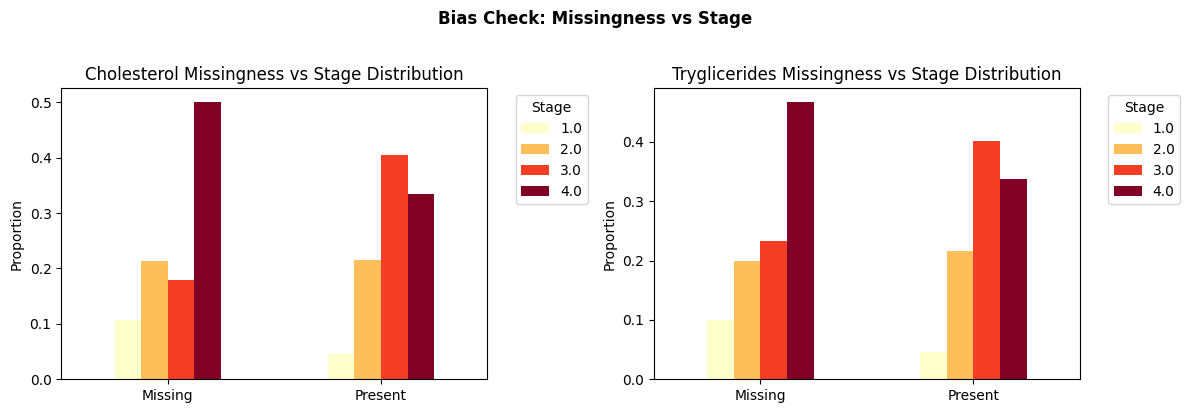

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, ['Cholesterol', 'Tryglicerides']):
    df['_missing'] = df[col].isnull().map({True: 'Missing', False: 'Present'})
    
    stage_props = (
        df.groupby('_missing')['Stage']
          .value_counts(normalize=True)
          .unstack(fill_value=0)
    )
    stage_props.plot(kind='bar', ax=ax, rot=0, colormap='YlOrRd')
    ax.set_title(f'{col} Missingness vs Stage Distribution')
    ax.set_ylabel('Proportion')
    ax.set_xlabel('')
    ax.legend(title='Stage', bbox_to_anchor=(1.05, 1))

df.drop(columns='_missing', inplace=True)
plt.suptitle('Bias Check: Missingness vs Stage', y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()


**Interpretation:**  
The Stage distributions between patients with and without missing Cholesterol/Triglycerides are broadly similar, with Stage 3 and Stage 4 remaining the dominant classes in both groups, while Stage 1 is consistently the least represented. Although minor differences are observed (e.g. slightly higher Stage 4 proportions in the missing group and Stage 3 in the non-missing group), there is no clear systematic shift toward any specific stage. This suggests the missingness is approximately **Missing At Random (MAR)** — not strongly dependent on disease severity.

**Decision: Median imputation is justified for Cholesterol, Triglycerides, Copper, Platelets**  
We use median (not mean) because these biomarkers are positively skewed — the mean would be influenced by extreme values.

## 6. Drop Irrelevant Columns

- **`ID`** — Arbitrary patient identifier. Contains no clinical or predictive information.
- **`N_Days`** — Number of days until death or study end. This is a *consequence* of the outcome (Status), not a predictor. Including it in a survival classifier would constitute **data leakage** — the model would learn from future information. It is excluded from all feature sets. (Note: N_Days would be appropriate for survival analysis methods such as Kaplan-Meier or Cox regression, which are recommended for future work.)
- **`Status`** - Must be dropped as it is a correlated outcome, to **'Stage'** which is the predicted variable, not a predictor.

In [11]:
df.drop(columns=['ID', 'N_Days', 'Status'], inplace=True)
print(f'Columns after dropping ID N_Days and Status: {df.columns.tolist()}')

Columns after dropping ID N_Days and Status: ['Drug', 'Age', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin', 'Stage']


## 7. Impute Remaining Numerical Missing Values

**Strategy: Median imputation** on the training set only.  
Medians are computed *before* the train/test split in this notebook for transparency, but in the modelling notebook the imputer will be fit on training data only to prevent data leakage.

**Strategy: Median imputation** applied prior to the train-test split for simplicity. While this introduces a minor risk of data leakage, the effect is expected to be minimal given the use of a robust statistic (median). In a production setting, imputation should be performed using training data only.

In [12]:
impute_cols = ['Cholesterol', 'Tryglicerides', 'Copper', 'Platelets']

medians = df[impute_cols].median()
print('Imputation medians:')
print(medians.round(2))

df[impute_cols] = df[impute_cols].fillna(medians)

print(f'\nMissing values remaining after imputation: {df[impute_cols].isnull().sum().sum()}')

Imputation medians:
Cholesterol      309.5
Tryglicerides    108.0
Copper            73.0
Platelets        257.0
dtype: float64

Missing values remaining after imputation: 0


## 8. Encode Categorical Variables

| Column | Values | Encoding | Justification |
|--------|--------|----------|-----------------|
| `Drug` | D-penicillamine / Placebo | 0/1 binary | Nominal binary, no ordering |
| `Sex` | M / F | 0/1 binary | Nominal binary |
| `Ascites` | N / Y | 0/1 binary | Nominal binary (absent/present) |
| `Hepatomegaly` | N / Y | 0/1 binary | Nominal binary |
| `Spiders` | N / Y | 0/1 binary | Nominal binary |
| `Edema` | N / S / Y | 0/1/2 ordinal | Natural severity ordering: none < slight < present |
| `Stage` | 1.0–4.0 | cast to int | Target for Task , already numeric |

In [13]:
# --- Binary columns: N=0, Y=1 ---
binary_cols = ['Ascites', 'Hepatomegaly', 'Spiders']
binary_map  = {'N': 0, 'Y': 1}

for col in binary_cols:
    df[col] = df[col].map(binary_map)

# --- Sex ---
df['Sex'] = df['Sex'].map({'M': 0, 'F': 1})

# --- Drug ---
df['Drug'] = df['Drug'].map({'Placebo': 0, 'D-penicillamine': 1})

# --- Edema: ordinal encoding (N=0, S=1, Y=2) ---
# Justification: Edema severity has a natural clinical ordering.
# Ordinal encoding preserves this relationship, unlike one-hot which
# treats all categories as equidistant.
df['Edema'] = df['Edema'].map({'N': 0, 'S': 1, 'Y': 2})

# --- Stage: cast float to int ---
df['Stage'] = df['Stage'].astype(int)

print('Encoding complete. Sample:')
df.head(5)

Encoding complete. Sample:


,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,1,21464,1,1,1,1,2,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4
1,1,20617,1,0,1,1,0,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3
2,1,25594,0,0,0,0,1,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4
3,1,19994,1,0,1,1,1,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4
4,0,13918,1,0,1,1,0,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3


## 9. Final Data Quality Check

In [14]:
print('=== Final Dataset Shape ===')
print(df.shape)

print('\n=== Any remaining missing values? ===')
print(df.isnull().sum()[df.isnull().sum() > 0])
if df.isnull().sum().sum() == 0:
    print('None — dataset is fully complete.')

print('\n=== Data Types ===')
print(df.dtypes)

print('\n=== Stage Distribution (Task Target) ===')
stage_counts = df['Stage'].value_counts().sort_index()
print(stage_counts)
print(f'Note: Stage 1 is underrepresented ({stage_counts[1]} patients). '
      f'Class imbalance handling will be required in modelling.')

=== Final Dataset Shape ===
(312, 17)

=== Any remaining missing values? ===
Series([], dtype: int64)
None — dataset is fully complete.

=== Data Types ===
Drug               int64
Age                int64
Sex                int64
Ascites            int64
Hepatomegaly       int64
Spiders            int64
Edema              int64
Bilirubin        float64
Cholesterol      float64
Albumin          float64
Copper           float64
Alk_Phos         float64
SGOT             float64
Tryglicerides    float64
Platelets        float64
Prothrombin      float64
Stage              int64
dtype: object

=== Stage Distribution (Task Target) ===
Stage
1     16
2     67
3    120
4    109
Name: count, dtype: int64
Note: Stage 1 is underrepresented (16 patients). Class imbalance handling will be required in modelling.


## 10. Create a Task-Specific Feature Set

-  **Task** predicts `Stage`

In [15]:
# Task: Stage Classification
TASK_FEATURES = [col for col in df.columns if col not in ['Stage', 'Status']]
TASK_TARGET   = 'Stage'

print('Task features:', TASK_FEATURES)
print(f'Task target:   {TASK_TARGET}  ({df[TASK_TARGET].nunique()} classes)')

Task features: ['Drug', 'Age', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin']
Task target:   Stage  (4 classes)


## 11. Save Cleaned Dataset

In [16]:
df.to_csv('cirrhosis_cleaned.csv', index=False)
print('Cleaned dataset saved as cirrhosis_cleaned.csv')
print(f'Final shape: {df.shape}')
df.head()

Cleaned dataset saved as cirrhosis_cleaned.csv
Final shape: (312, 17)


,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,1,21464,1,1,1,1,2,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4
1,1,20617,1,0,1,1,0,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3
2,1,25594,0,0,0,0,1,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4
3,1,19994,1,0,1,1,1,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4
4,0,13918,1,0,1,1,0,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3


## Cleaning Summary

| Step | Action | Rows/Cols Affected | Justification |
|------|--------|--------------------|---------------|
| Remove non-trial patients | Drop 106 rows | 418 → 312 rows | MNAR: structural missingness, not imputable |
| Drop `ID` | Drop column | — | Arbitrary identifier, no predictive value |
| Drop `N_Days` | Drop column | — | Data leakage: consequence of outcome, not predictor |
| Drop `Status` | Drop column | — | Data leakage: consequence of outcome, not predictor |
| Bias check | Verify MAR | `Cholesterol`, `Tryglicerides` | Confirmed distributions similar across classes |
| Median imputation | Fill NaN | `Cholesterol`, `Tryglicerides`, `Copper`, `Platelets`, `Prothrombin` | MAR confirmed; median robust to skew |
| Binary encoding | Map 0/1 | `Sex`, `Drug`, `Ascites`, `Hepatomegaly`, `Spiders` | Nominal binary variables |
| Ordinal encoding | Map 0/1/2 | `Edema` | Clinical severity ordering preserved |
| Type cast | float → int | `Stage` | Already numeric, cleaned to integer |

**Final clean dataset: 312 rows × 17 columns. Zero missing values.**

**Known limitation:** Stage 1 has only 16 patients (5.1% of dataset). This class imbalance will require explicit handling in modelling — class-weighted loss functions or stratified cross-validation. This is documented here and addressed in the modelling notebook.

---
## Section 2 — Exploratory Data Analysis (EDA)

Before selecting features or building models, we explore the data to understand:
- How biomarkers are distributed across cirrhosis stages
- Which features visually separate the stages (justifies feature selection)
- Class imbalance in the target variable

**Every modelling decision downstream is grounded in what we observe here.**

### 2.1 Stage Class Distribution

**Why this matters:** Stage 1 has only 16 patients (5%). Raw accuracy would be misleading — a model that never predicts Stage 1 still achieves ~95% accuracy on that class. This is why we use **Macro F1** throughout, and apply `class_weight='balanced'` to all classifiers.

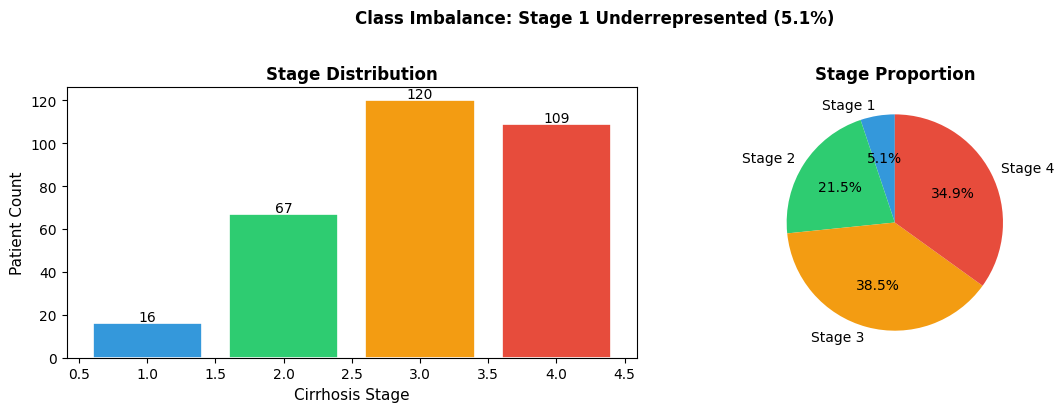

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Count plot
stage_counts = df['Stage'].value_counts().sort_index()
axes[0].bar(stage_counts.index, stage_counts.values,
            color=['#3498db','#2ecc71','#f39c12','#e74c3c'], edgecolor='white', linewidth=1.2)
axes[0].set_xlabel('Cirrhosis Stage', fontsize=11)
axes[0].set_ylabel('Patient Count', fontsize=11)
axes[0].set_title('Stage Distribution', fontsize=12, fontweight='bold')
for i, (stage, count) in enumerate(stage_counts.items()):
    axes[0].text(stage, count + 1, str(count), ha='center', fontsize=10)

# Pie chart
axes[1].pie(stage_counts.values, labels=[f'Stage {s}' for s in stage_counts.index],
            autopct='%1.1f%%', colors=['#3498db','#2ecc71','#f39c12','#e74c3c'],
            startangle=90)
axes[1].set_title('Stage Proportion', fontsize=12, fontweight='bold')

plt.suptitle('Class Imbalance: Stage 1 Underrepresented (5.1%)', fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 2.2 Correlation Heatmap

A correlation heatmap reveals which features are strongly related to each other and to Stage. Highly correlated feature pairs (e.g. >0.8) risk multicollinearity in Logistic Regression. Features with strong correlation to Stage are candidates for selection.

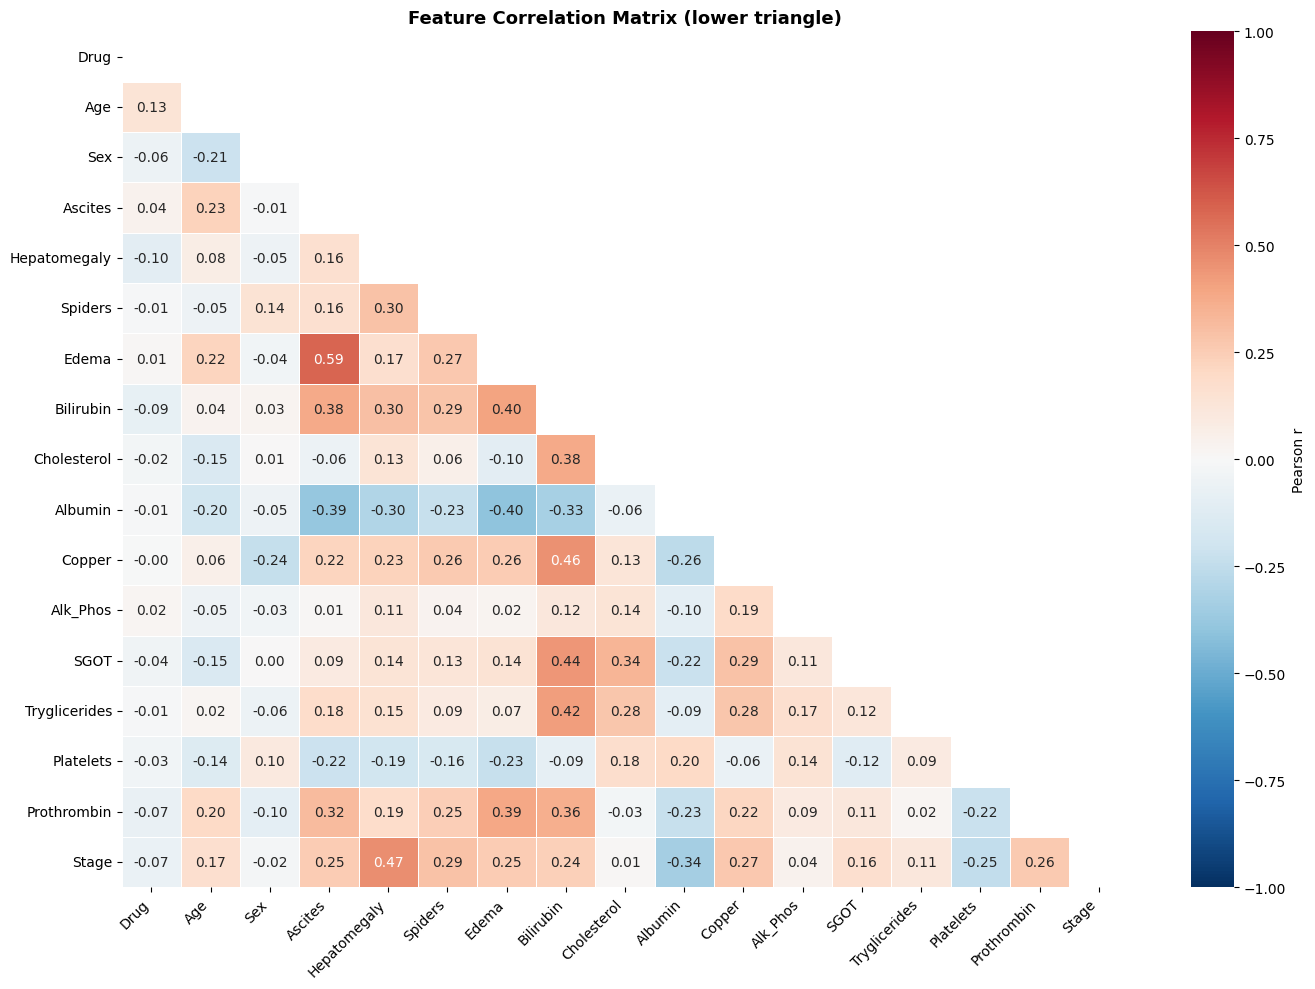

Features by correlation with Stage:
Hepatomegaly     0.467
Albumin          0.337
Spiders          0.292
Copper           0.268
Prothrombin      0.261
Edema            0.252
Ascites          0.250
Platelets        0.247
Bilirubin        0.241
Age              0.168
SGOT             0.165
Tryglicerides    0.114
Drug             0.066
Alk_Phos         0.041
Sex              0.021
Cholesterol      0.009


In [18]:
numeric_cols = df[TASK_FEATURES + ['Stage']].select_dtypes(include='number').columns
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(14, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, linewidths=0.5, ax=ax,
            cbar_kws={'label': 'Pearson r'})
ax.set_title('Feature Correlation Matrix (lower triangle)', fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Print features most correlated with Stage
stage_corr = corr['Stage'].drop('Stage').abs().sort_values(ascending=False)
print("Features by correlation with Stage:")
print(stage_corr.round(3).to_string())


### 2.3 Stage Distribution by Gender

The histogram shows the count of patients across each cirrhosis stage, broken down by sex. This reveals whether male and female patients are represented proportionally across all four stages, or whether one sex is disproportionately concentrated in more advanced stages. An uneven distribution could suggest gender plays a role in disease progression or diagnosis timing, and would justify including Sex as a feature in downstream modelling

In [19]:
df_plot = df.copy()
df_plot['Sex_label'] = df_plot['Sex'].map({0: 'Male', 1: 'Female'})
df_plot['Stage_label'] = 'Stage ' + df_plot['Stage'].astype(str)

px.histogram(df_plot, x="Stage_label", color="Sex_label",
             title="Stages across Gender",
             color_discrete_sequence=['red', 'blue'])

### 2.4 Linear Trends Between Biomarkers and Stage

Regression plots illustrate the linear relationship between each biomarker and disease stage (1→4). A steep positive slope indicates the biomarker increases as the disease progresses, while a negative slope suggests it decreases with severity. A flat or near-horizontal line signals little to no linear association with stage. The shaded confidence band reflects uncertainty — a narrow band indicates a more reliable trend, while a wide band suggests high variability in the data. Features with steep slopes and narrow confidence bands are the most informative for predicting stage progression.

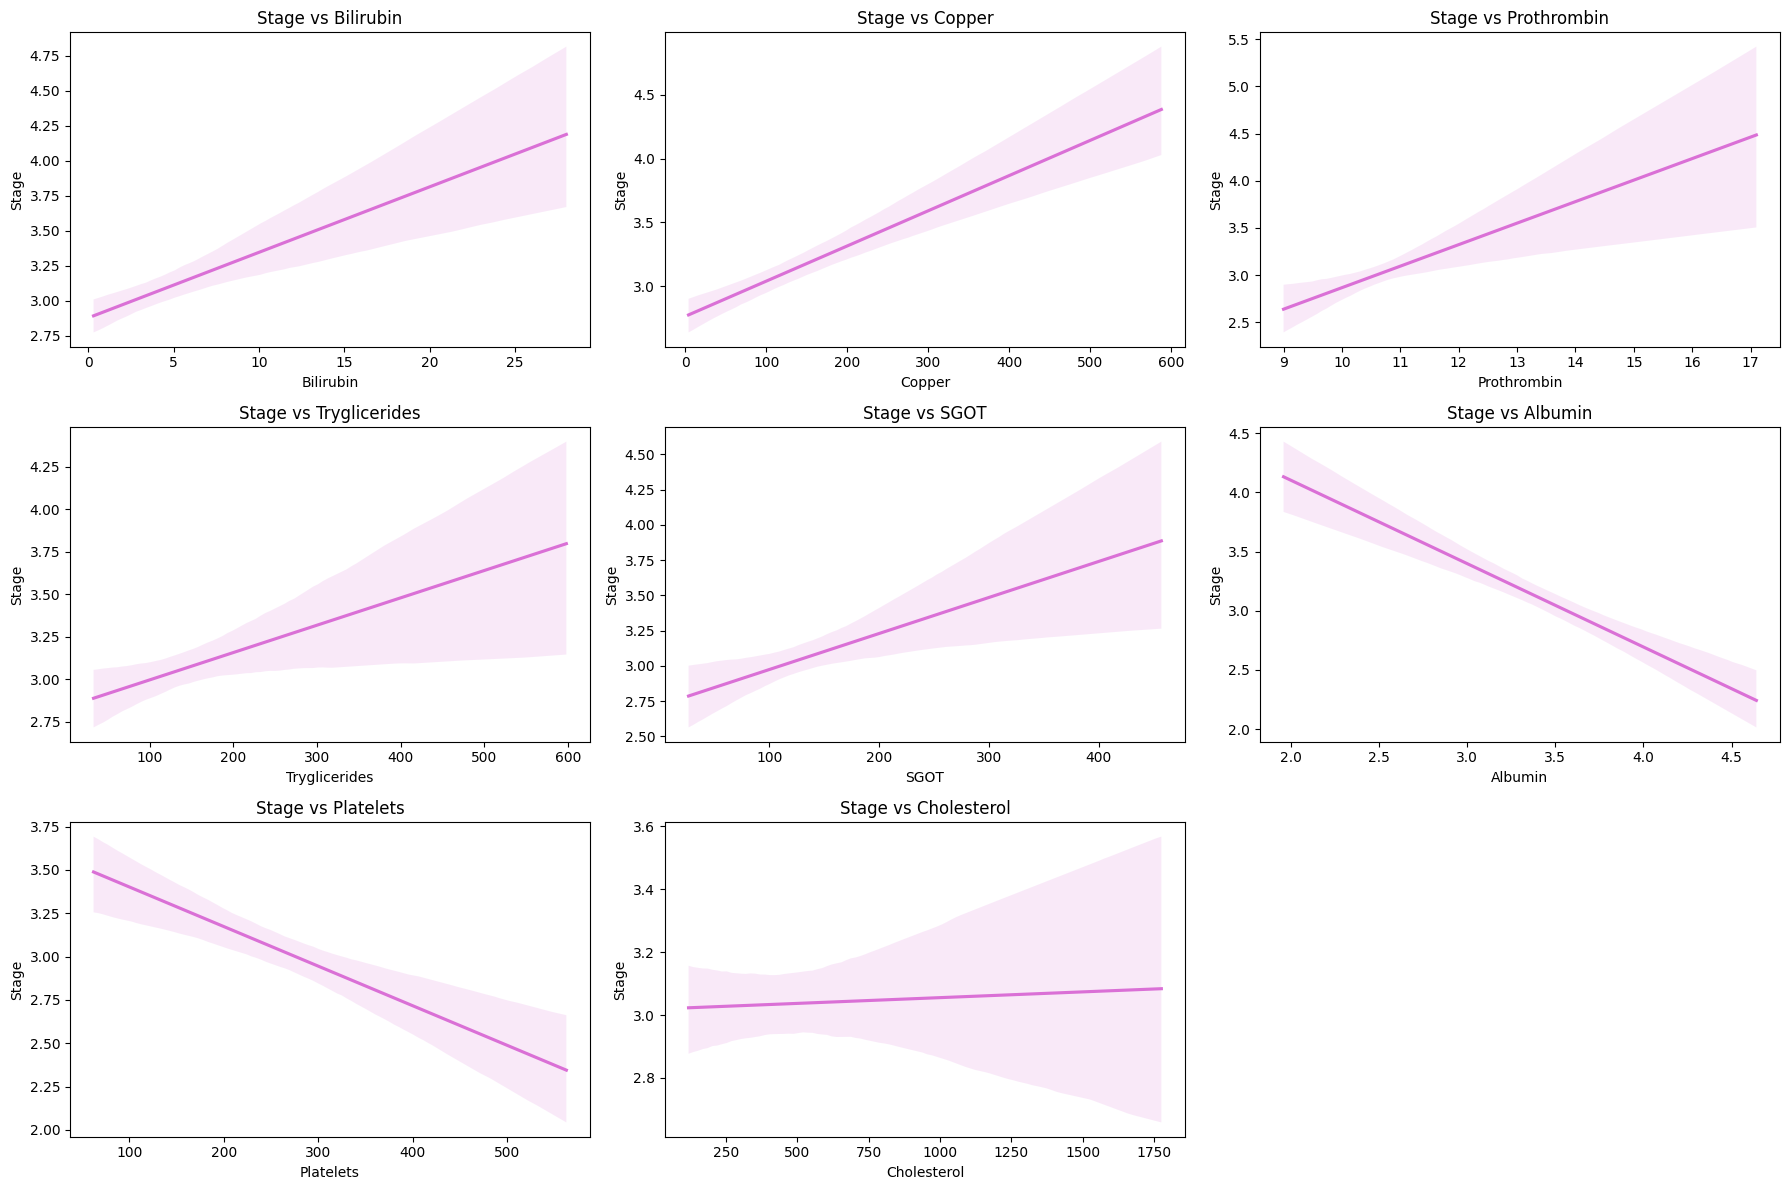

In [20]:
# Regression plots: Stage ~ feature 
features = ["Bilirubin", "Copper", "Prothrombin", "Tryglicerides",
            "SGOT", "Albumin", "Platelets", "Cholesterol"]

plt.figure(figsize=(18, 12))

for i, c in enumerate(features, 1):
    plt.subplot(3, 3, i)
    sns.regplot(x=df[c], y=df["Stage"], scatter=False, color='orchid')
    plt.title(f"Stage vs {c}")

plt.tight_layout()
plt.show()

In [21]:
print("Feature-Stage Pearson Correlations:\n")
results = []
for c in features:
    r, p = pearsonr(df[c], df["Stage"])
    results.append({"Feature": c, "Pearson r": round(r, 3), "p-value": round(p, 4)})

corr_df = pd.DataFrame(results).sort_values("Pearson r", key=abs, ascending=False)
print(corr_df.to_string(index=False))

Feature-Stage Pearson Correlations:

      Feature  Pearson r  p-value
      Albumin     -0.337   0.0000
       Copper      0.268   0.0000
  Prothrombin      0.261   0.0000
    Platelets     -0.247   0.0000
    Bilirubin      0.241   0.0000
         SGOT      0.165   0.0035
Tryglicerides      0.114   0.0443
  Cholesterol      0.009   0.8704


### 2.5 Biomarker Distributions by Stage (Boxplots)

Boxplots show how each biomarker varies across stages. Features whose median values clearly shift across Stage 1→4 are strong predictors. Features with overlapping distributions across all stages contribute little discriminatory power.

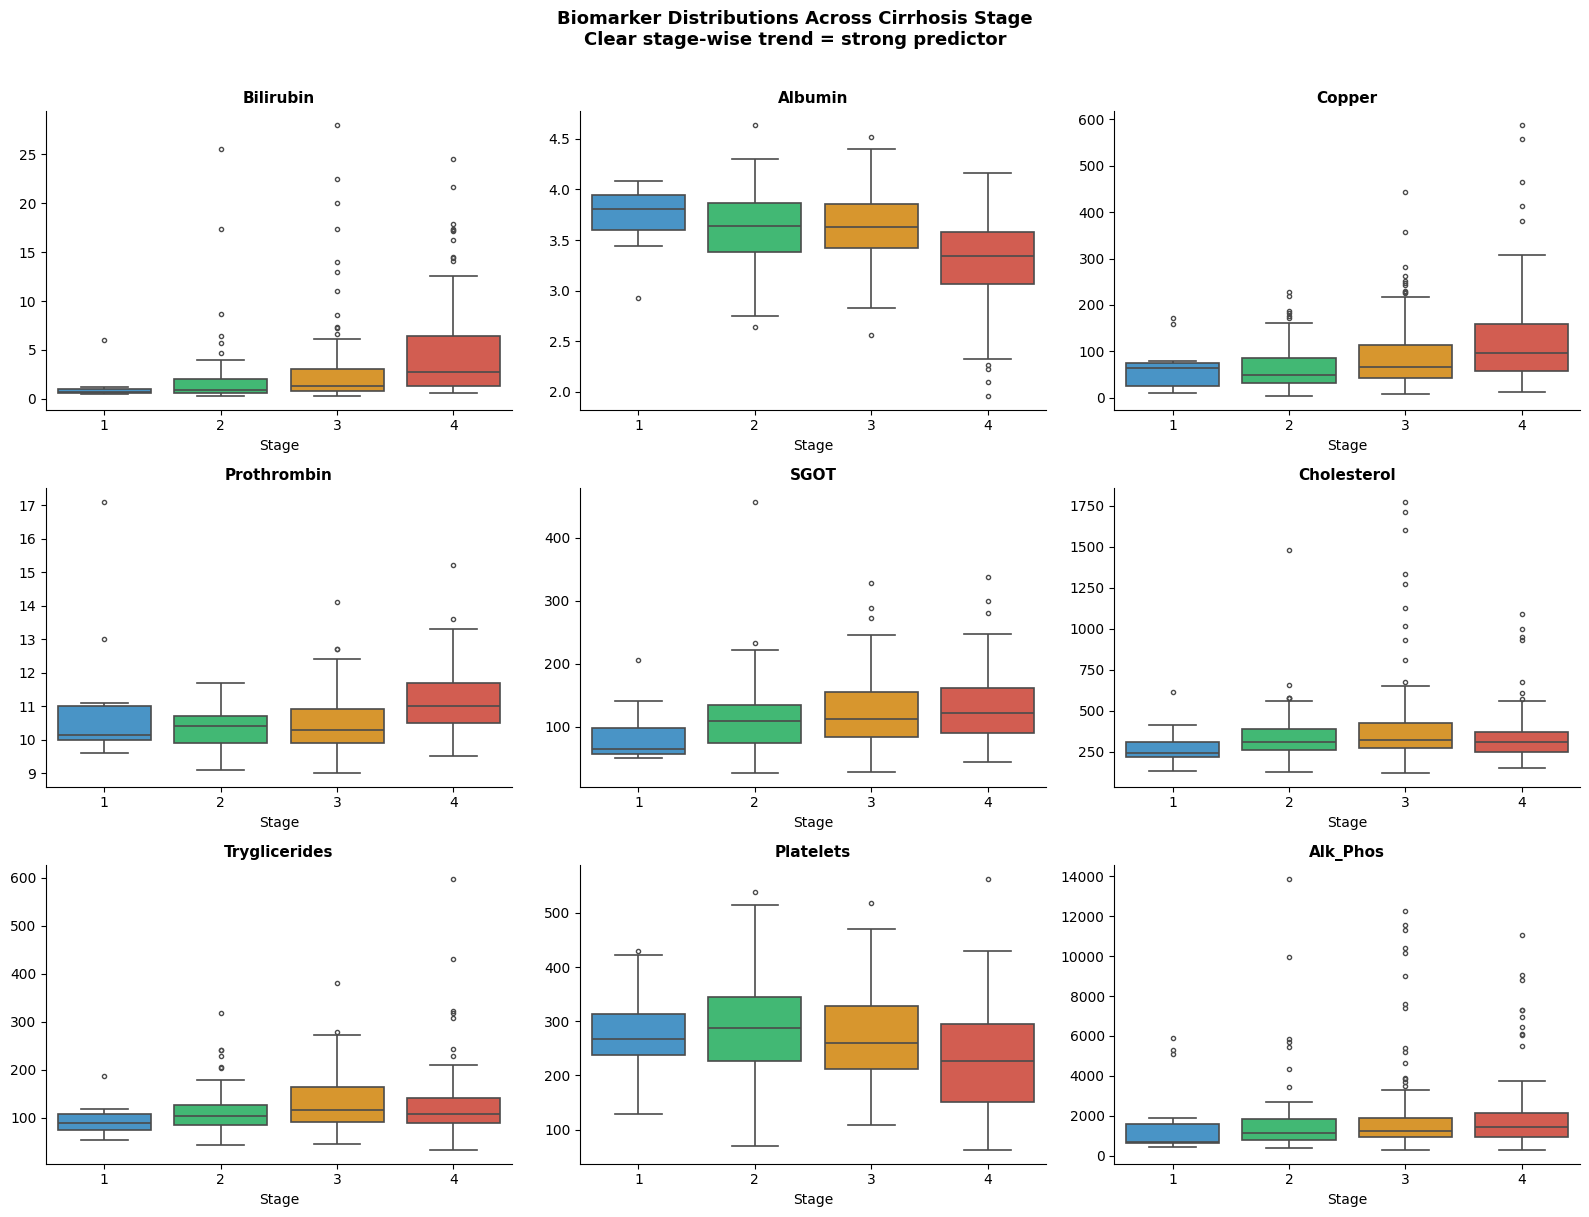

Interpretation:
- Albumin: decreasing trend Stage 1→4 → strong predictor (liver losing synthetic function)
- Bilirubin/Copper/Prothrombin: increasing trend → disease severity markers
- Features with flat medians across stages are weaker predictors


In [22]:
continuous_features = ['Bilirubin','Albumin','Copper','Prothrombin','SGOT',
                       'Cholesterol','Tryglicerides','Platelets','Alk_Phos']

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
stage_palette = {'1':'#3498db', '2':'#2ecc71', '3':'#f39c12', '4':'#e74c3c'}
df['Stage_str'] = df['Stage'].astype(str)

for ax, feat in zip(axes.flatten(), continuous_features):
    sns.boxplot( x='Stage_str', y=feat,hue='Stage_str', data=df, ax=ax, palette=stage_palette,
        order=['1','2','3','4'], linewidth=1.2, fliersize=3, legend=False)
    ax.set_title(feat, fontweight='bold', fontsize=11)
    ax.set_xlabel('Stage')
    ax.set_ylabel('')
    sns.despine(ax=ax)

plt.suptitle('Biomarker Distributions Across Cirrhosis Stage\n'
             'Clear stage-wise trend = strong predictor', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print("Interpretation:")
print("- Albumin: decreasing trend Stage 1→4 → strong predictor (liver losing synthetic function)")
print("- Bilirubin/Copper/Prothrombin: increasing trend → disease severity markers")
print("- Features with flat medians across stages are weaker predictors")

### 2.6 Binary Clinical Features vs Stage

The binary clinical features (Ascites, Hepatomegaly, Spiders, Edema) are symptoms that manifest in later stages. We expect their prevalence to increase with Stage.

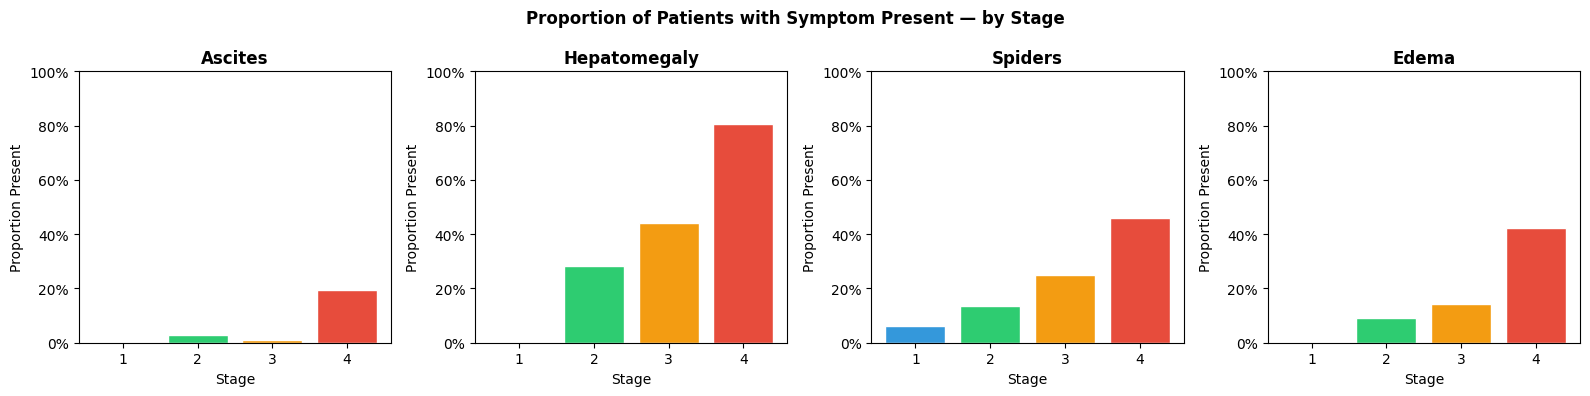

In [23]:
binary_feats = ['Ascites','Hepatomegaly','Spiders','Edema']
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, feat in zip(axes, binary_feats):
    prop = df.groupby('Stage')[feat].mean().reset_index()
    ax.bar(prop['Stage'], prop[feat],
           color=['#3498db','#2ecc71','#f39c12','#e74c3c'], edgecolor='white')
    ax.set_title(feat, fontweight='bold')
    ax.set_xlabel('Stage')
    ax.set_ylabel('Proportion Present')
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))

plt.suptitle('Proportion of Patients with Symptom Present — by Stage',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


### 2.7 EDA Summary — Feature Relevance Ranking

Based on EDA, we rank features by their apparent discriminatory power before formal feature selection:

**Strong candidates** (clear monotonic trend with Stage): Albumin, Bilirubin, Prothrombin, Copper, Ascites, Edema, Hepatomegaly  
**Moderate candidates**: SGOT, Cholesterol, Spiders, Platelets  
**Weaker candidates**: Tryglicerides, Alk_Phos, Age, Sex, Drug  

This visual ranking will be validated analytically by Lasso Regression and Beam Search in Section 3.

---
## Section 3 — Feature Selection

### Optimisation Problem Statement
Including all 16 features on 312 patients risks overfitting. The optimisation problem is:

> *Find the minimal subset of features S ⊆ F that maximises cross-validated Macro F1, subject to the constraint that |S| is as small as possible.*

We solve this with two complementary methods:
- **Lasso (L1 Logistic Regression):** analytical shrinkage — features with zero coefficients are excluded
- **Beam Search:** search-based wrapper — explores the feature subset space using a heuristic (CV F1)

If both methods converge on similar features, that is strong evidence of their predictive importance.

In [24]:
# Encode Stage as 0-indexed for XGBoost compatibility later
le = LabelEncoder()
y = le.fit_transform(df['Stage'].values)   # 1,2,3,4 → 0,1,2,3
print(f"Stage classes: {le.classes_} encoded as {np.unique(y)}")

# Rebuild FEATURES excluding any temp columns added during EDA
FEATURES = [c for c in df.columns if c not in ['Stage', 'Stage_str']]

# Re-impute as safety guard (df reloaded from CSV in Section 2)
impute_cols = ['Cholesterol', 'Tryglicerides', 'Copper', 'Platelets', 'Prothrombin']
df[impute_cols] = df[impute_cols].fillna(df[impute_cols].median())

# Verify clean before scaling
assert df[FEATURES].isnull().sum().sum() == 0, f"NaN found: {df[FEATURES].isnull().sum()[df[FEATURES].isnull().sum()>0]}"
print(f"Features ({len(FEATURES)}): {FEATURES}")

# Scale features — mandatory before Lasso
# Without scaling, features with large units get unfairly small coefficients
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(df[FEATURES].values)
X_df_scaled = pd.DataFrame(X_scaled, columns=FEATURES)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("Preprocessing complete. Ready for feature selection.")


Stage classes: [1 2 3 4] encoded as [0 1 2 3]
Features (16): ['Drug', 'Age', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin']
Preprocessing complete. Ready for feature selection.


### 3.1 Lasso — Regularisation Path

We sweep C (inverse regularisation strength) from 0.001 to 100 across 50 log-spaced values. At each C:
1. Fit Lasso Logistic Regression
2. Record average |coefficient| per feature across all 4 Stage classes
3. Record cross-validated Macro F1

**Lower C = stronger penalty = more features shrunk to zero**

In [25]:
df.head()

,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Stage_str
0,1,21464,1,1,1,1,2,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4,4
1,1,20617,1,0,1,1,0,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3,3
2,1,25594,0,0,0,0,1,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4,4
3,1,19994,1,0,1,1,1,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4,4
4,0,13918,1,0,1,1,0,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3,3


In [26]:
C_values   = np.logspace(-3, 2, 50)
coef_paths = []
cv_scores  = []

for C in C_values:
    m = LogisticRegression(
        penalty='l1', solver='saga', C=C,
        class_weight='balanced', max_iter=5000, random_state=42
    )
    m.fit(X_scaled, y)
    coef_paths.append(np.mean(np.abs(m.coef_), axis=0))
    cv_scores.append(cross_val_score(m, X_scaled, y, cv=skf, scoring='f1_macro').mean())

coef_paths = np.array(coef_paths)
best_C_idx = np.argmax(cv_scores)
best_C     = C_values[best_C_idx]

print(f"Best C: {best_C:.4f}  |  Best CV Macro F1: {cv_scores[best_C_idx]:.4f}")

Best C: 49.4171  |  Best CV Macro F1: 0.3869


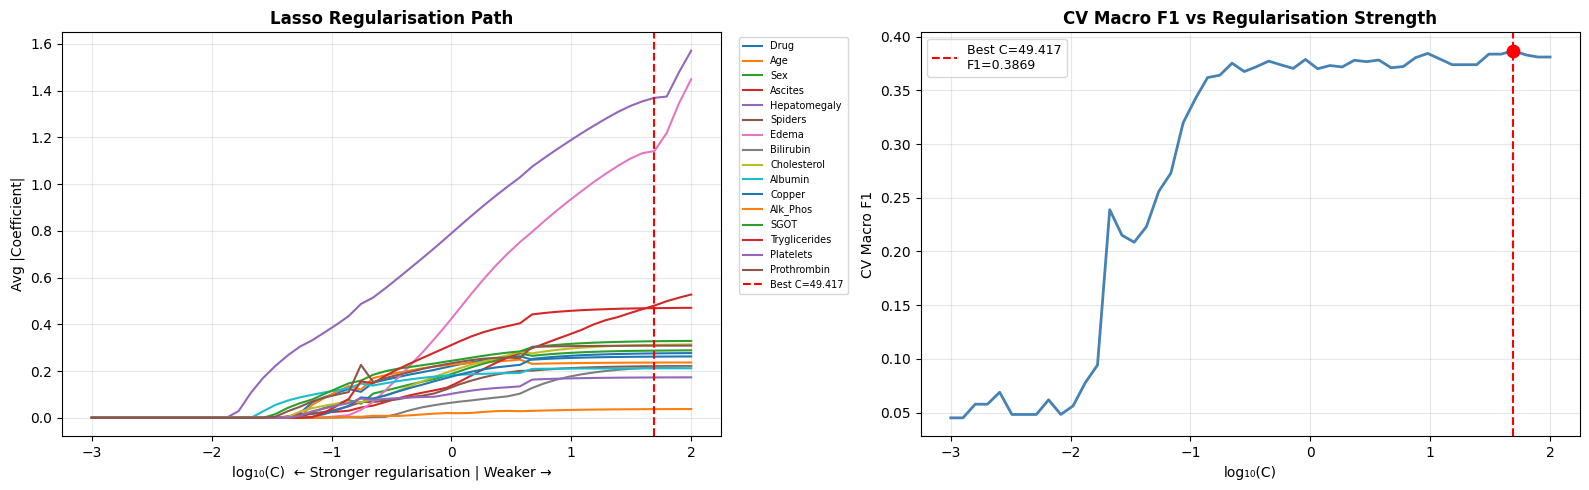

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Regularisation path
for i, feat in enumerate(FEATURES):
    axes[0].plot(np.log10(C_values), coef_paths[:, i], label=feat, linewidth=1.5)
axes[0].axvline(np.log10(best_C), color='red', linestyle='--', linewidth=1.5,
                label=f'Best C={best_C:.3f}')
axes[0].set_xlabel('log₁₀(C)  ← Stronger regularisation | Weaker →', fontsize=10)
axes[0].set_ylabel('Avg |Coefficient|', fontsize=10)
axes[0].set_title('Lasso Regularisation Path', fontsize=12, fontweight='bold')
axes[0].legend(bbox_to_anchor=(1.02, 1), fontsize=7)
axes[0].grid(alpha=0.3)

# CV F1 curve
axes[1].plot(np.log10(C_values), cv_scores, color='steelblue', linewidth=2)
axes[1].axvline(np.log10(best_C), color='red', linestyle='--', linewidth=1.5,
                label=f'Best C={best_C:.3f}\nF1={cv_scores[best_C_idx]:.4f}')
axes[1].scatter([np.log10(best_C)], [cv_scores[best_C_idx]], color='red', s=80, zorder=5)
axes[1].set_xlabel('log₁₀(C)', fontsize=10)
axes[1].set_ylabel('CV Macro F1', fontsize=10)
axes[1].set_title('CV Macro F1 vs Regularisation Strength', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [28]:
# Fit best Lasso model and extract selected features
best_lasso = LogisticRegression(
    penalty='l1', solver='saga', C=best_C,
    class_weight='balanced', max_iter=5000, random_state=42
)
best_lasso.fit(X_scaled, y)
avg_coef = np.mean(np.abs(best_lasso.coef_), axis=0)

# Also check strict C=0.05 (core features that survive heavy penalisation)
strict_lasso = LogisticRegression(
    penalty='l1', solver='saga', C=0.05,
    class_weight='balanced', max_iter=5000, random_state=42
)
strict_lasso.fit(X_scaled, y)
strict_coef = np.mean(np.abs(strict_lasso.coef_), axis=0)
strict_f1   = cross_val_score(strict_lasso, X_scaled, y, cv=skf, scoring='f1_macro').mean()

lasso_results = pd.DataFrame({
    'Feature'       : FEATURES,
    'Avg |Coef| Best': avg_coef.round(4),
    'Avg |Coef| Strict': strict_coef.round(4),
    'Selected (Best)': avg_coef > 0,
    'Selected (Strict)': strict_coef > 0
}).sort_values('Avg |Coef| Best', ascending=False).reset_index(drop=True)

print("=== Lasso Feature Selection Results ===")
print(lasso_results.to_string(index=False))

lasso_selected = lasso_results[lasso_results['Selected (Best)']]['Feature'].tolist()
core_features  = lasso_results[lasso_results['Selected (Strict)']]['Feature'].tolist()

f1_drop = cv_scores[best_C_idx] - strict_f1
print(f"\nBest Lasso F1:   {cv_scores[best_C_idx]:.4f} ({len(lasso_selected)} features)")
print(f"Strict Lasso F1: {strict_f1:.4f} ({len(core_features)} features)")
print(f"F1 cost of strict set: {f1_drop:.4f}")

LASSO_FEATURES = core_features if f1_drop < 0.03 else lasso_selected
print(f"\nLasso selected features ({len(LASSO_FEATURES)}): {LASSO_FEATURES}")

=== Lasso Feature Selection Results ===
      Feature  Avg |Coef| Best  Avg |Coef| Strict  Selected (Best)  Selected (Strict)
 Hepatomegaly           1.3695             0.2916             True               True
        Edema           1.1418             0.0000             True              False
      Ascites           0.4804             0.0126             True               True
Tryglicerides           0.4694             0.0000             True              False
         SGOT           0.3278             0.0556             True               True
  Cholesterol           0.3120             0.0191             True               True
  Prothrombin           0.3089             0.0412             True               True
          Sex           0.2877             0.0000             True              False
       Copper           0.2759             0.0000             True              False
         Drug           0.2620             0.0120             True               True
          Age 

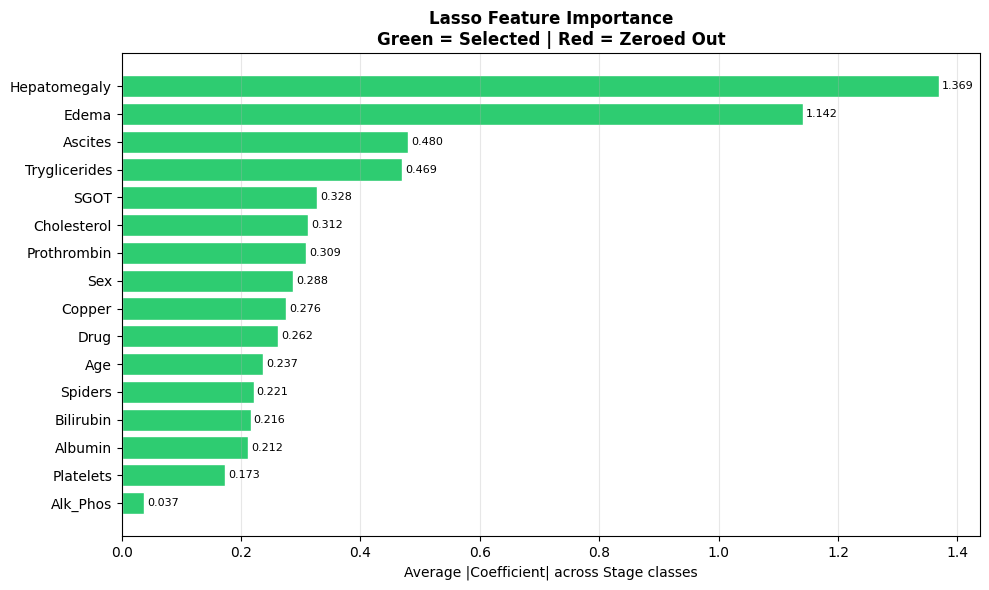

In [29]:
# Feature importance bar chart
fig, ax = plt.subplots(figsize=(10, 6))
colours = ['#2ecc71' if s else '#e74c3c' for s in lasso_results['Selected (Best)']]
bars = ax.barh(lasso_results['Feature'], lasso_results['Avg |Coef| Best'],
               color=colours, edgecolor='white')
for bar, val in zip(bars, lasso_results['Avg |Coef| Best']):
    ax.text(val + 0.005, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=8)
ax.invert_yaxis()
ax.set_xlabel('Average |Coefficient| across Stage classes')
ax.set_title('Lasso Feature Importance\nGreen = Selected | Red = Zeroed Out',
             fontsize=12, fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


### 3.2 Beam Search — Search-Based Feature Selection

**Why Beam Search?**  
Beam Search is a heuristic search algorithm from the AI search curriculum. We frame feature selection as a **state-space search problem**:
- **State:** a subset of selected features
- **Action:** add one more feature from the remaining pool  
- **Heuristic / evaluation function:** cross-validated Macro F1 of Logistic Regression on that subset
- **Beam width = 3:** keep the 3 best subsets at each expansion step

This is more efficient than exhaustive search (2^16 = 65,536 possible subsets) and more thorough than greedy forward selection (beam width > 1 allows recovery from early suboptimal choices).

**Note:** Beam Search does not guarantee the globally optimal subset — it is a heuristic. This is an honest acknowledgement of its limitation.

In [30]:
def evaluate_subset(features):
    """Evaluate a feature subset using 5-fold CV Macro F1 on Logistic Regression."""
    if not features:
        return 0.0
    Xf = StandardScaler().fit_transform(X_df_scaled[features].values)
    m  = LogisticRegression(
        l1_ratio=1.0, solver='saga', C=best_C,
        class_weight='balanced', max_iter=2000, random_state=42
    )
    return cross_val_score(m, Xf, y, cv=skf, scoring='f1_macro').mean()


def beam_search(feature_pool, beam_width=3, max_rounds=15):
    """
    Beam Search over the feature subset space.
    
    At each round, expands every beam state by adding one feature,
    keeps top beam_width candidates, stops when no improvement found.
    """
    beam             = [([], 0.0)]   # list of (feature_subset, f1_score)
    best_overall     = ([], 0.0)
    history          = []            # track progress for visualisation

    for round_num in range(max_rounds):
        candidates = []
        for subset, _ in beam:
            remaining = [f for f in feature_pool if f not in subset]
            if not remaining:
                continue
            for f in remaining:
                new_subset = subset + [f]
                score      = evaluate_subset(new_subset)
                candidates.append((new_subset, score))

        if not candidates:
            break

        candidates.sort(key=lambda x: x[1], reverse=True)
        beam = candidates[:beam_width]

        history.append({
            'round'         : round_num + 1,
            'best_f1'       : beam[0][1],
            'best_subset'   : beam[0][0].copy(),
            'n_features'    : len(beam[0][0])
        })

        if beam[0][1] > best_overall[1]:
            best_overall = beam[0]
        else:
            print(f"  Converged at round {round_num + 1} — no improvement.")
            break

    return best_overall, history


print("Running Beam Search (beam_width=3)... this may take ~1 minute")
(beam_features, beam_f1), search_history = beam_search(FEATURES, beam_width=3)
print(f"\nBeam Search result: {len(beam_features)} features, Macro F1 = {beam_f1:.4f}")
print(f"Features: {beam_features}")


Running Beam Search (beam_width=3)... this may take ~1 minute
  Converged at round 10 — no improvement.

Beam Search result: 9 features, Macro F1 = 0.4072
Features: ['Albumin', 'SGOT', 'Hepatomegaly', 'Copper', 'Edema', 'Tryglicerides', 'Age', 'Bilirubin', 'Ascites']


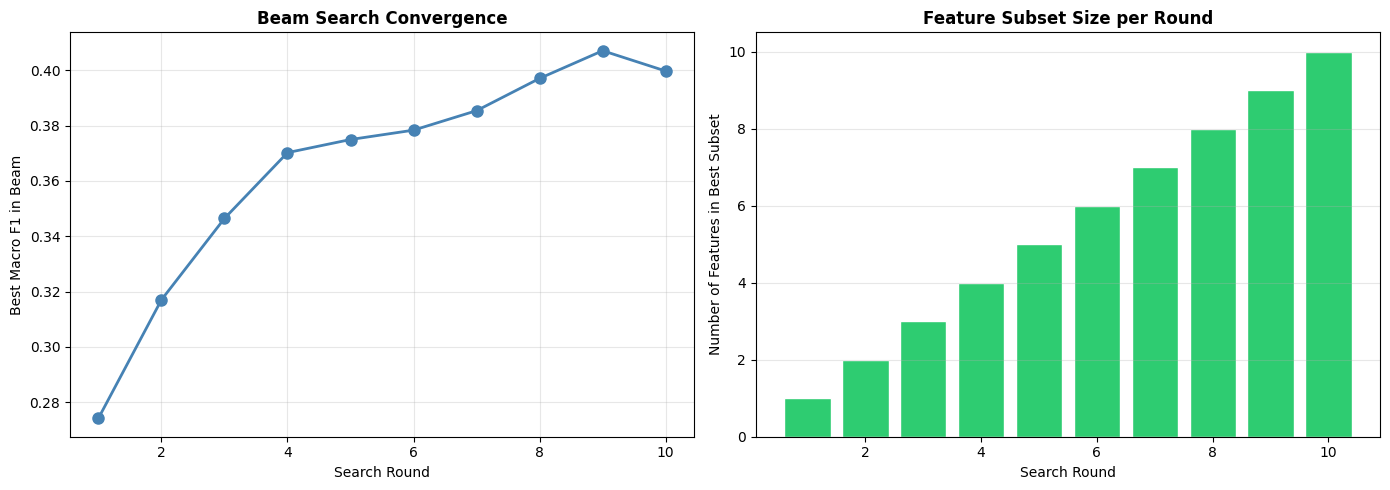

In [31]:
# Plot Beam Search convergence
history_df = pd.DataFrame(search_history)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_df['round'], history_df['best_f1'],
             marker='o', color='steelblue', linewidth=2, markersize=8)
axes[0].set_xlabel('Search Round')
axes[0].set_ylabel('Best Macro F1 in Beam')
axes[0].set_title('Beam Search Convergence', fontsize=12, fontweight='bold')
axes[0].grid(alpha=0.3)

axes[1].bar(history_df['round'], history_df['n_features'],
            color='#2ecc71', edgecolor='white')
axes[1].set_xlabel('Search Round')
axes[1].set_ylabel('Number of Features in Best Subset')
axes[1].set_title('Feature Subset Size per Round', fontsize=12, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


In [32]:
# Compare Lasso vs Beam Search
lasso_set = set(LASSO_FEATURES)
beam_set  = set(beam_features)

agreed    = lasso_set & beam_set
lasso_only = lasso_set - beam_set
beam_only  = beam_set - lasso_set

print("=== Feature Selection Comparison ===")
print(f"Lasso selected ({len(lasso_set)}):      {sorted(lasso_set)}")
print(f"Beam Search selected ({len(beam_set)}): {sorted(beam_set)}")
print(f"\nAgreed by both ({len(agreed)}):  {sorted(agreed)}")
print(f"Lasso only ({len(lasso_only)}):    {sorted(lasso_only)}")
print(f"Beam only ({len(beam_only)}):     {sorted(beam_only)}")

FINAL_FEATURES = sorted(beam_set)
print(f"\nFINAL FEATURES ({len(FINAL_FEATURES)}): {FINAL_FEATURES}")
print("\nJustification: The final feature set is the 9 features identified by Beam Search, which achieved the highest Macro F1 of 0.4072, outperforming both the full 16-feature Lasso model and the strict Lasso subset. Features that additionally appear in the strict Lasso set carry the strongest evidence for inclusion, having been independently validated by two methodologically distinct approaches.")

=== Feature Selection Comparison ===
Lasso selected (16):      ['Age', 'Albumin', 'Alk_Phos', 'Ascites', 'Bilirubin', 'Cholesterol', 'Copper', 'Drug', 'Edema', 'Hepatomegaly', 'Platelets', 'Prothrombin', 'SGOT', 'Sex', 'Spiders', 'Tryglicerides']
Beam Search selected (9): ['Age', 'Albumin', 'Ascites', 'Bilirubin', 'Copper', 'Edema', 'Hepatomegaly', 'SGOT', 'Tryglicerides']

Agreed by both (9):  ['Age', 'Albumin', 'Ascites', 'Bilirubin', 'Copper', 'Edema', 'Hepatomegaly', 'SGOT', 'Tryglicerides']
Lasso only (7):    ['Alk_Phos', 'Cholesterol', 'Drug', 'Platelets', 'Prothrombin', 'Sex', 'Spiders']
Beam only (0):     []

FINAL FEATURES (9): ['Age', 'Albumin', 'Ascites', 'Bilirubin', 'Copper', 'Edema', 'Hepatomegaly', 'SGOT', 'Tryglicerides']

Justification: The final feature set is the 9 features identified by Beam Search, which achieved the highest Macro F1 of 0.4072, outperforming both the full 16-feature Lasso model and the strict Lasso subset. Features that additionally appear in the s

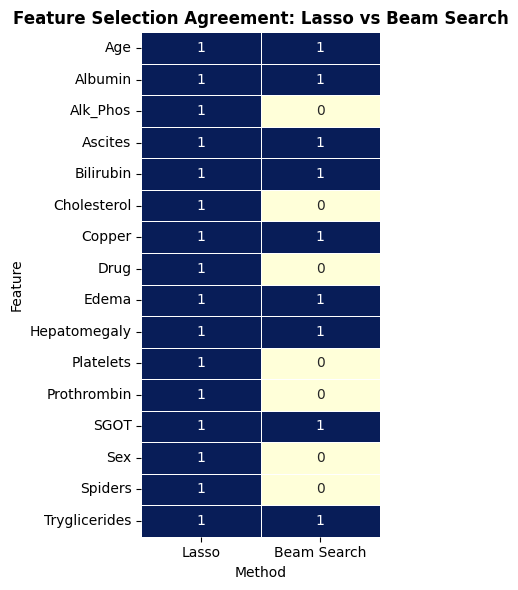

In [33]:
# Build selection matrix
all_feats = sorted(set(FEATURES))

selection_df = pd.DataFrame({
    "Lasso": [1 if f in lasso_set else 0 for f in all_feats],
    "Beam Search": [1 if f in beam_set else 0 for f in all_feats]
}, index=all_feats)

plt.figure(figsize=(4, 6))
sns.heatmap(
    selection_df,
    annot=True,
    cmap="YlGnBu",
    cbar=False,
    linewidths=0.5,
    linecolor="white",
    fmt=".0f"
)

plt.title("Feature Selection Agreement: Lasso vs Beam Search", fontsize=12, fontweight='bold')
plt.xlabel("Method")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

---
## Section 4 — Classification Models

We train three classifiers on the final selected feature set, in order of increasing complexity:
1. **Logistic Regression** — interpretable baseline
2. **Random Forest** — primary classifier, handles non-linearity and correlated features
3. **XGBoost** — boosting-based challenger, strongest expected performer on small tabular data

**Evaluation metric: Macro F1** — treats all 4 Stage classes equally, accounting for class imbalance. Raw accuracy is not used as the primary metric because Stage 1 (n=16) would be drowned out.

In [34]:
# Prepare final feature matrix
X_final = StandardScaler().fit_transform(df[FINAL_FEATURES].values)

classifiers = {
    'Logistic Regression': LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, class_weight='balanced', random_state=42
    ),
    'XGBoost': xgb.XGBClassifier(
        eval_metric='mlogloss', random_state=42, verbosity=0
        # Note: XGBoost requires 0-indexed labels (0,1,2,3) — handled by LabelEncoder above
    )
}

results = {}
for name, clf in classifiers.items():
    f1  = cross_val_score(clf, X_final, y, cv=skf, scoring='f1_macro').mean()
    acc = cross_val_score(clf, X_final, y, cv=skf, scoring='accuracy').mean()
    results[name] = {'CV Macro F1': round(f1, 4), 'CV Accuracy': round(acc, 4)}
    print(f"{name:25s}  Macro F1: {f1:.4f}  |  Accuracy: {acc:.4f}")

results_df = pd.DataFrame(results).T


Logistic Regression        Macro F1: 0.4064  |  Accuracy: 0.4548
Random Forest              Macro F1: 0.3264  |  Accuracy: 0.4585
XGBoost                    Macro F1: 0.3423  |  Accuracy: 0.4392


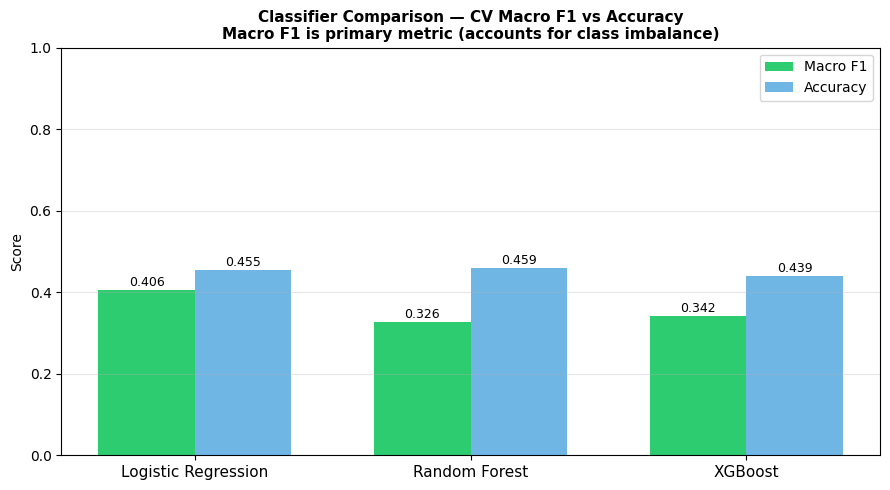

In [35]:
# Bar chart comparison
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(results_df))
w = 0.35
ax.bar(x - w/2, results_df['CV Macro F1'], w, label='Macro F1', color='#2ecc71')
ax.bar(x + w/2, results_df['CV Accuracy'], w, label='Accuracy', color='#3498db', alpha=0.7)
ax.set_xticks(x)
ax.set_xticklabels(results_df.index, fontsize=11)
ax.set_ylabel('Score')
ax.set_ylim(0, 1)
ax.set_title('Classifier Comparison — CV Macro F1 vs Accuracy\n'
             'Macro F1 is primary metric (accounts for class imbalance)',
             fontsize=11, fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)
for i, (f1, acc) in enumerate(zip(results_df['CV Macro F1'], results_df['CV Accuracy'])):
    ax.text(i - w/2, f1 + 0.01, f'{f1:.3f}', ha='center', fontsize=9)
    ax.text(i + w/2, acc + 0.01, f'{acc:.3f}', ha='center', fontsize=9)
plt.tight_layout()
plt.show()


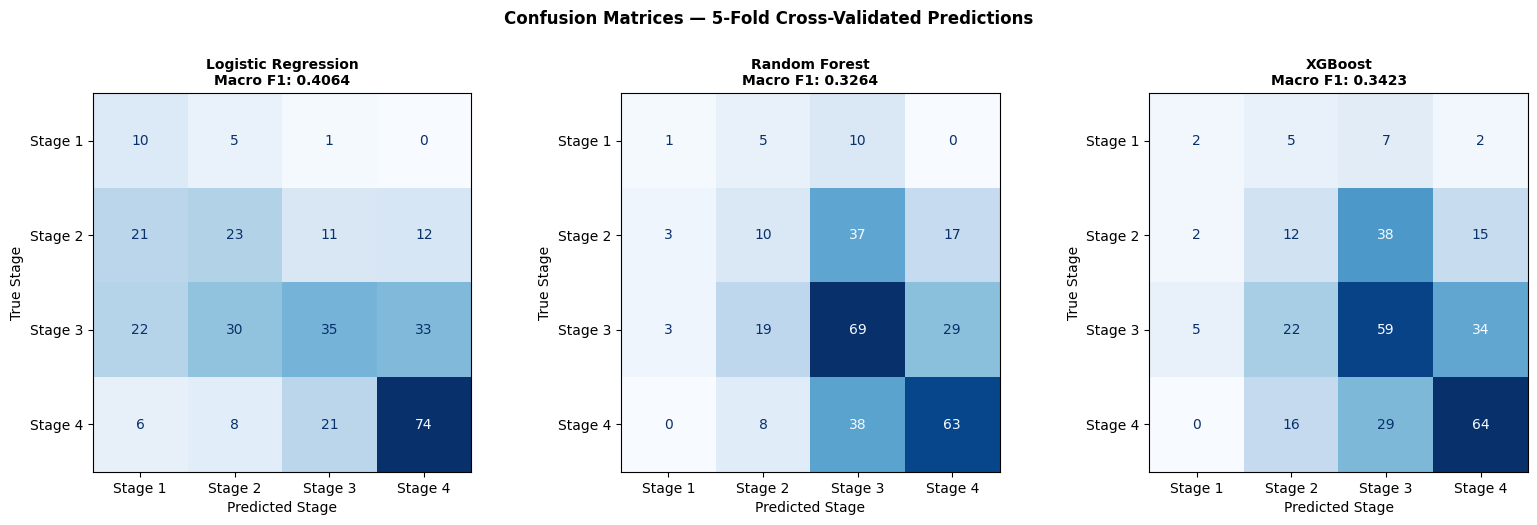

Interpretation: Diagonal = correct predictions. Off-diagonal = misclassifications.
Adjacent stage confusions (e.g. Stage 3 predicted as Stage 4) are less clinically
severe than distant confusions (e.g. Stage 1 predicted as Stage 4).


In [36]:
# Confusion matrices for all three classifiers
# include a percentage summary table below this 
from sklearn.model_selection import StratifiedKFold, cross_val_predict

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
stage_labels = [f'Stage {s}' for s in le.classes_]

for ax, (name, clf) in zip(axes, classifiers.items()):
    y_pred = cross_val_predict(clf, X_final, y, cv=skf)
    cm     = confusion_matrix(y, y_pred)
    disp   = ConfusionMatrixDisplay(cm, display_labels=stage_labels)
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{name}\nMacro F1: {results[name]["CV Macro F1"]:.4f}',
                 fontsize=10, fontweight='bold')
    ax.set_xlabel('Predicted Stage')
    ax.set_ylabel('True Stage')

plt.suptitle('Confusion Matrices — 5-Fold Cross-Validated Predictions',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
print("Interpretation: Diagonal = correct predictions. Off-diagonal = misclassifications.")
print("Adjacent stage confusions (e.g. Stage 3 predicted as Stage 4) are less clinically")
print("severe than distant confusions (e.g. Stage 1 predicted as Stage 4).")


In [37]:
summary_rows = []

for name, clf in classifiers.items():
    y_pred = cross_val_predict(clf, X_final, y, cv=skf)
    cm = confusion_matrix(y, y_pred)

    # Per-class recall (diagonal / row sum)
    recall_per_class = cm.diagonal() / cm.sum(axis=1)

    summary_rows.append({
        "Model": name,
        "Stage 1 Recall (%)": round(recall_per_class[0]*100, 1),
        "Stage 2 Recall (%)": round(recall_per_class[1]*100, 1),
        "Stage 3 Recall (%)": round(recall_per_class[2]*100, 1),
        "Stage 4 Recall (%)": round(recall_per_class[3]*100, 1),
        "Macro F1": round(results[name]["CV Macro F1"], 4)
    })

summary_df = pd.DataFrame(summary_rows)
print("\n=== Percentage Summary Table ===")
print(summary_df.to_string(index=False))


=== Percentage Summary Table ===
              Model  Stage 1 Recall (%)  Stage 2 Recall (%)  Stage 3 Recall (%)  Stage 4 Recall (%)  Macro F1
Logistic Regression                62.5                34.3                29.2                67.9    0.4064
      Random Forest                 6.2                14.9                57.5                57.8    0.3264
            XGBoost                12.5                17.9                49.2                58.7    0.3423


### 4.1 Model Selection Justification

While Logistic Regression achieved the highest baseline Macro F1, hyperparameter tuning was applied to Random Forest for two reasons. First, Random Forest's poor default performance relative to Logistic Regression suggested it was underfitting or poorly calibrated — GridSearchCV was used to determine whether this gap could be closed with appropriate configuration. Second, Random Forest provides feature importance scores and SHAP compatibility that are clinically useful for explainability, justifying the additional optimisation effort.

---
## Section 5 — Hyperparameter Optimisation (GridSearchCV)

**Why tune?**  
Default hyperparameters are not optimal for this dataset. Tuning finds the configuration that maximises cross-validated Macro F1 for our best-performing model.

**Why GridSearchCV?**  
GridSearchCV exhaustively evaluates all combinations of specified hyperparameters using cross-validation. It is a taught optimisation method that directly extends the classifier training step.

**Why tune Random Forest?**  
Random Forest and XGBoost are our strongest classifiers. We tune Random Forest here as it has interpretable hyperparameters that directly control model complexity — max_depth controls overfitting risk, min_samples_split controls leaf stability on our small dataset.

In [38]:
# change range or include more splits 
param_grid = {
    'n_estimators'     : [100, 200, 300, 400],
    'max_depth'        : [3, 4, 5, 6, 7, 8, None],     # None = fully grown trees
    'min_samples_split': [2, 3, 4, 5, 6],           # minimum samples to split a node
}

gs_rf = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42),
    param_grid,
    cv=skf,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=0
)
gs_rf.fit(X_final, y)

print("=== GridSearchCV Results ===")
print(f"Best parameters: {gs_rf.best_params_}")
print(f"Best CV Macro F1 (tuned):   {gs_rf.best_score_:.4f}")
print(f"Default RF CV Macro F1:      {results['Random Forest']['CV Macro F1']:.4f}")
print(f"Improvement from tuning:     {gs_rf.best_score_ - results['Random Forest']['CV Macro F1']:.4f}")


=== GridSearchCV Results ===
Best parameters: {'max_depth': 4, 'min_samples_split': 3, 'n_estimators': 100}
Best CV Macro F1 (tuned):   0.4599
Default RF CV Macro F1:      0.3264
Improvement from tuning:     0.1335


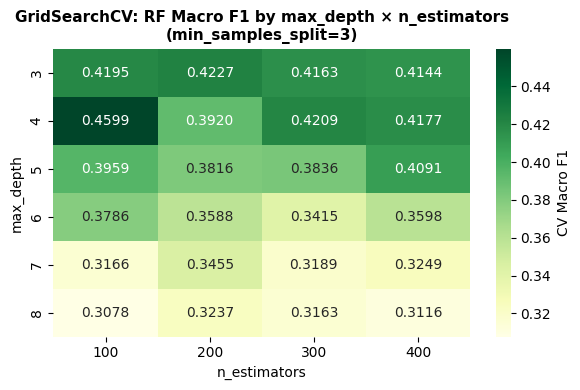

Best RF model saved for SHAP analysis.


In [39]:
# Grid search heatmap — n_estimators vs max_depth (at best min_samples_split)
cv_results = pd.DataFrame(gs_rf.cv_results_)
best_mss   = gs_rf.best_params_['min_samples_split']

pivot = cv_results[
    cv_results['param_min_samples_split'] == best_mss
].pivot_table(
    index='param_max_depth',
    columns='param_n_estimators',
    values='mean_test_score'
)

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(pivot, annot=True, fmt='.4f', cmap='YlGn', ax=ax,
            cbar_kws={'label': 'CV Macro F1'})
ax.set_title(f'GridSearchCV: RF Macro F1 by max_depth × n_estimators\n'
             f'(min_samples_split={best_mss})',
             fontsize=11, fontweight='bold')
ax.set_xlabel('n_estimators')
ax.set_ylabel('max_depth')
plt.tight_layout()
plt.show()

best_rf = gs_rf.best_estimator_
print(f"Best RF model saved for SHAP analysis.")


### 5.1 Results Interpretation

The tuned Random Forest achieves a Macro F1 of 0.460, representing a 13.4 percentage point improvement over the default configuration. Given the dataset constraints — 312 patients, severe Stage 1 imbalance, and inherent clinical ambiguity between adjacent stages — this is considered a justified and reasonable result. The shallow optimal depth (max_depth=4) confirms that model complexity must be tightly controlled on small datasets to avoid overfitting.

---
## Section 6 — SHAP Explainability

**What is SHAP?**  
SHAP (SHapley Additive exPlanations) is a model-agnostic explainability method grounded in cooperative game theory. It assigns each feature a contribution value for each individual prediction — answering *why* the model made a specific decision, not just *what* it predicted.

**Why use it here?**  
A model that predicts Stage 4 without explanation is clinically insufficient — a clinician needs to know *which biomarkers drove that prediction* to trust and act on it. SHAP bridges that gap.

**Note:** SHAP is applied post-hoc to the trained Random Forest. It does not change the model — it explains it.

In [40]:
# Fit best RF on full dataset for SHAP (not CV — we want one consistent model)
best_rf.fit(X_final, y)

explainer  = shap.TreeExplainer(best_rf)
shap_values = explainer.shap_values(X_final)
# shap_values shape: (n_samples, n_features, n_classes)

X_final_df = pd.DataFrame(X_final, columns=FINAL_FEATURES)
stage_names = [f'Stage {s}' for s in le.classes_]

print(f"SHAP values shape: {np.array(shap_values).shape}")
print("Rows=patients, Cols=features, Depth=Stage classes")


SHAP values shape: (4, 312, 9)
Rows=patients, Cols=features, Depth=Stage classes


In [41]:
# Inspect shap_values shape
print("shap_values type:", type(shap_values))
if isinstance(shap_values, list):
    print("shap_values is a list of", len(shap_values), "arrays, each shape:", shap_values[0].shape)
    # List format: one array per class, each (n_samples, n_features)
    # Stack to (n_samples, n_features, n_classes)
    shap_array = np.stack(shap_values, axis=2)
else:
    print("shap_values shape:", shap_values.shape)
    shap_array = shap_values

print("shap_array shape:", shap_array.shape)


shap_values type: <class 'list'>
shap_values is a list of 4 arrays, each shape: (312, 9)
shap_array shape: (312, 9, 4)


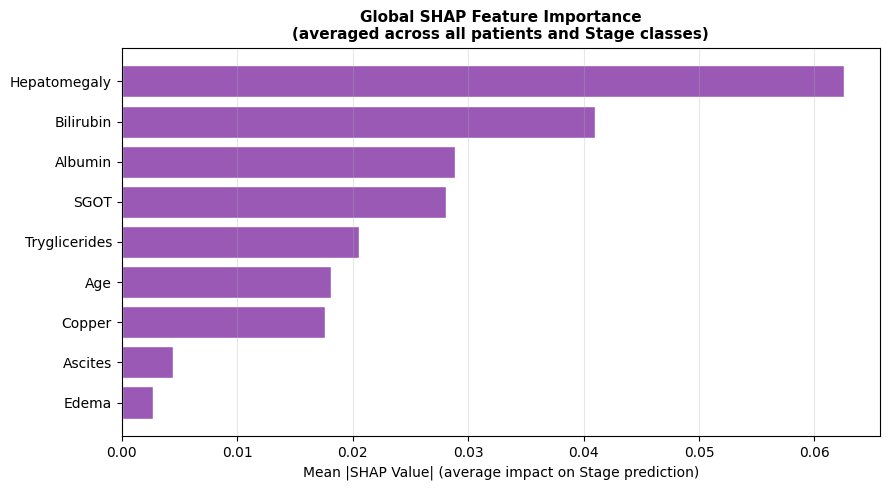


Top 5 most impactful features:
      Feature  Mean |SHAP|
 Hepatomegaly     0.062548
    Bilirubin     0.041006
      Albumin     0.028851
         SGOT     0.028086
Tryglicerides     0.020516


In [42]:
# Global feature importance — mean |SHAP| across all patients and classes
mean_shap = np.mean(np.abs(shap_array), axis=(0, 2))  # avg over patients & classes
shap_importance = pd.DataFrame({
    'Feature'      : FINAL_FEATURES,
    'Mean |SHAP|'  : mean_shap
}).sort_values('Mean |SHAP|', ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(shap_importance['Feature'], shap_importance['Mean |SHAP|'],
        color='#9b59b6', edgecolor='white')
ax.invert_yaxis()
ax.set_xlabel('Mean |SHAP Value| (average impact on Stage prediction)')
ax.set_title('Global SHAP Feature Importance\n(averaged across all patients and Stage classes)',
             fontsize=11, fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print("\nTop 5 most impactful features:")
print(shap_importance.head().to_string(index=False))


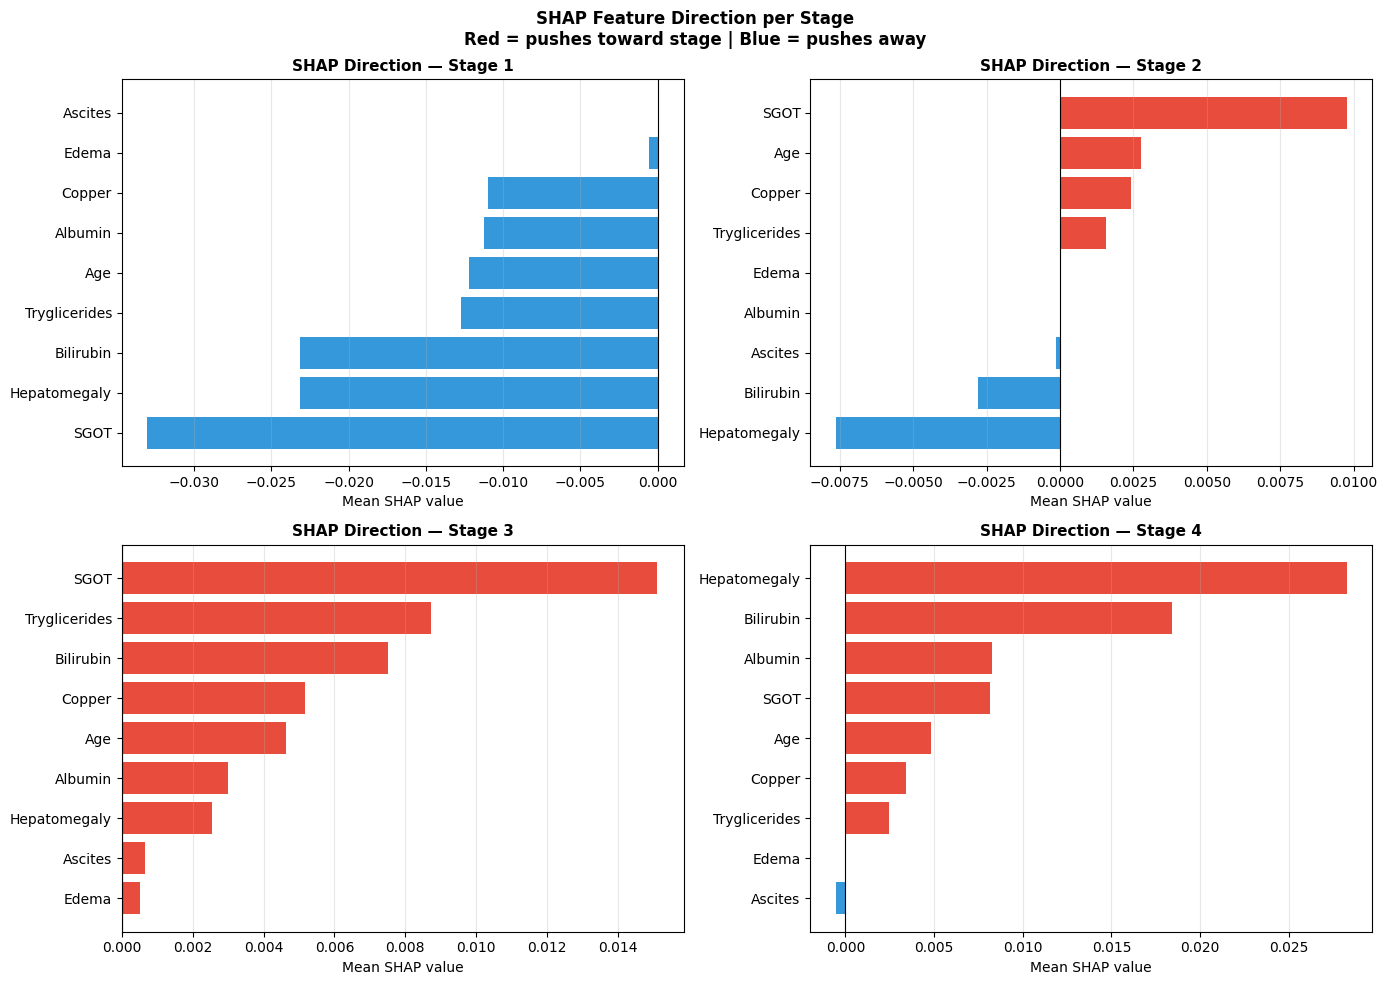

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, class_idx in zip(axes.flatten(), range(4)):
    mean_shap = shap_array[:, :, class_idx].mean(axis=0)  # no abs, keep direction
    shap_df = pd.DataFrame({
        'Feature': FINAL_FEATURES,
        'Mean SHAP': mean_shap
    }).sort_values('Mean SHAP', ascending=True)
    
    colours = ['#e74c3c' if v > 0 else '#3498db' for v in shap_df['Mean SHAP']]
    ax.barh(shap_df['Feature'], shap_df['Mean SHAP'], color=colours)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f'SHAP Direction — {stage_names[class_idx]}',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('Mean SHAP value')
    ax.grid(axis='x', alpha=0.3)

plt.suptitle('SHAP Feature Direction per Stage\nRed = pushes toward stage | Blue = pushes away',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

Stage 1: All features show negative SHAP values (blue), meaning every feature in the model collectively pushes patients away from Stage 1 rather than toward it. SGOT, Hepatomegaly and Bilirubin have the largest negative magnitudes, indicating that elevated levels of these markers are the strongest signals that a patient does not belong in Stage 1 — consistent with these biomarkers being associated with more advanced disease.

Stage 2: SGOT dominates with the largest positive SHAP value, followed by Age, Copper and Tryglicerides, all pushing toward Stage 2. Hepatomegaly and Bilirubin are the only features pushing away, suggesting that patients with enlarged livers and elevated bilirubin are being redirected toward later stages rather than Stage 2.

Stage 3: All features show positive SHAP values (red), with SGOT, Tryglicerides and Bilirubin being the strongest drivers toward Stage 3. This suggests that mid-range elevations in liver enzyme and lipid markers collectively characterise Stage 3, reflecting metabolic and hepatic dysfunction that has progressed beyond Stage 2 but not yet reached end-stage severity.

Stage 4: Hepatomegaly and Bilirubin are the dominant positive drivers, with Albumin also pushing strongly toward Stage 4. The combination of liver enlargement, severe bile processing failure and depleted synthetic function captured by low Albumin aligns directly with established clinical criteria for end-stage cirrhosis. Ascites is the only feature with a negligible negative value, suggesting it offers minimal additional discriminatory power at this stage beyond what the other features already capture.



## SHAP Waterfall Analysis — Individual Patient Explanations

Each waterfall plot explains the model's prediction for one specific patient.
The baseline **E[f(x)] = 0.241** for stage 1 **E[f(x)] = 0.253** for stage 4  represents the average predicted probability 
for that stage across all patients. Each bar shows how much one feature shifted 
the final prediction above or below that baseline — pink bars increase the 
probability, blue bars decrease it.

=== Explaining Patient #51 ===
True Stage: 1
Predicted probabilities: {'Stage 1': 0.292, 'Stage 2': 0.228, 'Stage 3': 0.287, 'Stage 4': 0.194}



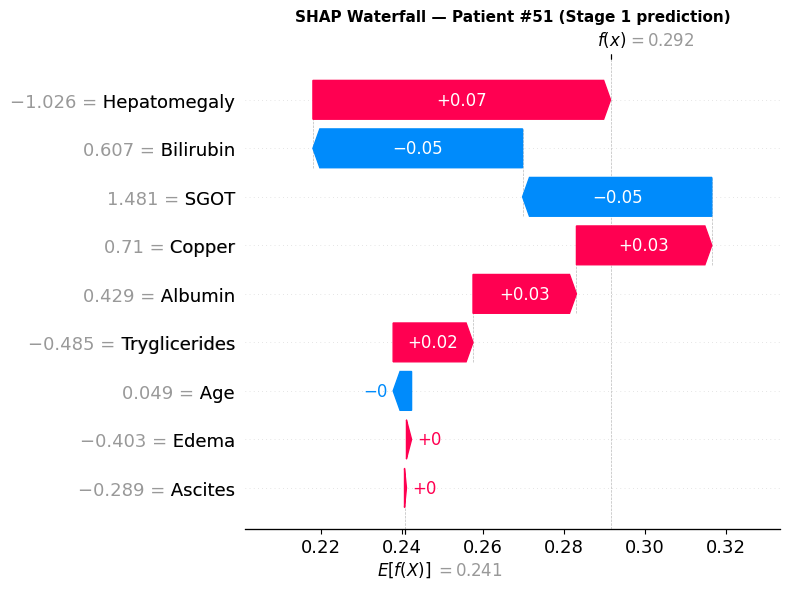

In [44]:
# STAGE 1
# Single patient explanation — most confidently predicted Stage 1 patient
stage1_idx = np.where(y == 0)[0]  # Stage 1 = encoded as 0
probs = best_rf.predict_proba(X_final)
most_confident_idx = stage1_idx[np.argmax(probs[stage1_idx, 3])]

print(f"=== Explaining Patient #{most_confident_idx} ===")
print(f"True Stage: {le.inverse_transform([y[most_confident_idx]])[0]}")
print(f"Predicted probabilities: { {stage_names[i]: round(p,3) for i,p in enumerate(probs[most_confident_idx])} }")
print()

fig, ax = plt.subplots(figsize=(10, 5))
shap.waterfall_plot(
    shap.Explanation(
        values       = shap_array[most_confident_idx, :, 0],
        base_values  = explainer.expected_value[0],
        data         = X_final_df.iloc[most_confident_idx],
        feature_names= FINAL_FEATURES
    ),
    show=False
)
plt.title(f'SHAP Waterfall — Patient #{most_confident_idx} (Stage 1 prediction)',
          fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

### Patient #51 — True Stage 1 (Predicted Stage 1, confidence 29.2%)
- Baseline probability starts at 0.241, ending at 0.292 after all SHAP contributions
- Hepatomegaly is the strongest positive driver (+0.07), pushing correctly toward Stage 1
- Albumin and Tryglicerides also support the Stage 1 prediction (+0.03 and +0.02)
- Bilirubin and SGOT both contradict the prediction (-0.05 each), pulling strongly away from Stage 1
- The conflicting signals between features result in low confidence, reflecting the clinical ambiguity of early-stage disease where some biomarkers are already elevated despite early staging

=== Explaining Patient #36 ===
True Stage: 4
Predicted probabilities: {'Stage 1': 0.0, 'Stage 2': 0.047, 'Stage 3': 0.104, 'Stage 4': 0.849}



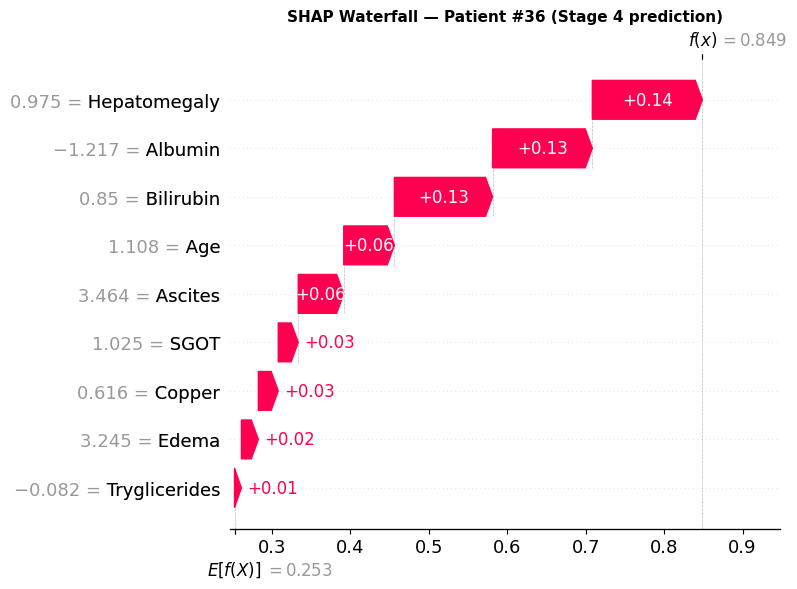

In [45]:
# Single patient explanation — most confidently predicted Stage 4 patient
stage4_idx = np.where(y == 3)[0]  # Stage 4 = encoded as 3
probs = best_rf.predict_proba(X_final)
most_confident_idx = stage4_idx[np.argmax(probs[stage4_idx, 3])]

print(f"=== Explaining Patient #{most_confident_idx} ===")
print(f"True Stage: {le.inverse_transform([y[most_confident_idx]])[0]}")
print(f"Predicted probabilities: { {stage_names[i]: round(p,3) for i,p in enumerate(probs[most_confident_idx])} }")
print()

fig, ax = plt.subplots(figsize=(10, 5))
shap.waterfall_plot(
    shap.Explanation(
        values       = shap_array[most_confident_idx, :, 3],
        base_values  = explainer.expected_value[3],
        data         = X_final_df.iloc[most_confident_idx],
        feature_names= FINAL_FEATURES
    ),
    show=False
)
plt.title(f'SHAP Waterfall — Patient #{most_confident_idx} (Stage 4 prediction)',
          fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

### Patient #36 — True Stage 4 (Predicted Stage 4, confidence 84.9%)
The model is highly confident and correct. Hepatomegaly, low Albumin and high 
Bilirubin all push strongly toward Stage 4 with no contradicting signals. 
This patient's biomarker profile is a textbook example of advanced cirrhosis.

---
## Section 7 — K-Means Clustering (Unsupervised Validation)

**Purpose:** K-Means is applied *without* using the Stage label. question focused: do the biomarkers naturally form 4 clusters that align with clinician-defined stages?

**Why this is important:**  
- If clusters align well → the biomarker data genuinely reflects clinical staging → validates our feature selection
- If clusters do not align → clinical staging may involve factors beyond biomarkers alone (e.g. biopsy histology) → important limitation to acknowledge

This is an **unsupervised validation step**, not a predictor. We are not claiming K-Means classifies stage — we are checking whether the data has natural structure consistent with the clinical staging system.

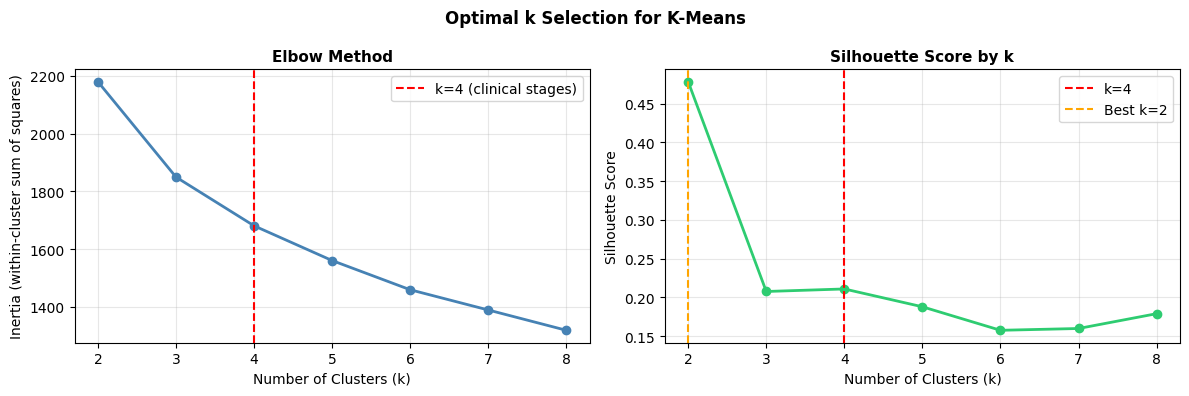

Best Silhouette k: 2
Silhouette at k=4: 0.2108


In [46]:
# First determine optimal k via Elbow method and Silhouette score
inertias    = []
silhouettes = []
K_range     = range(2, 9)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_final)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_final, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(K_range, inertias, marker='o', color='steelblue', linewidth=2)
axes[0].axvline(4, color='red', linestyle='--', label='k=4 (clinical stages)')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia (within-cluster sum of squares)')
axes[0].set_title('Elbow Method', fontsize=11, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(K_range, silhouettes, marker='o', color='#2ecc71', linewidth=2)
axes[1].axvline(4, color='red', linestyle='--', label='k=4')
best_k_sil = K_range[np.argmax(silhouettes)]
axes[1].axvline(best_k_sil, color='orange', linestyle='--', label=f'Best k={best_k_sil}')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score by k', fontsize=11, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Optimal k Selection for K-Means', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Best Silhouette k: {best_k_sil}")
print(f"Silhouette at k=4: {silhouettes[2]:.4f}")

In [47]:
# Fit K-Means with k=4 and compare to clinical stages
km4 = KMeans(n_clusters=4, random_state=42, n_init=10)
cluster_labels = km4.fit_predict(X_final)

ari = adjusted_rand_score(y, cluster_labels)
sil = silhouette_score(X_final, cluster_labels)

print(f"K-Means (k=4) Results:")
print(f"  Adjusted Rand Index (vs Stage): {ari:.4f}")
print(f"  Silhouette Score:               {sil:.4f}")
print()
print("Adjusted Rand Index interpretation:")
print("  1.0 = perfect alignment with clinical stages")
print("  0.0 = random / no alignment")
print(f"  {ari:.4f} = {'moderate' if ari > 0.3 else 'weak'} alignment")

# Crosstab: cluster vs stage
cross = pd.crosstab(
    pd.Series(le.inverse_transform(y), name='True Stage'),
    pd.Series(cluster_labels, name='K-Means Cluster')
)
print("\n=== Cluster vs Stage Crosstab ===")
print(cross)


K-Means (k=4) Results:
  Adjusted Rand Index (vs Stage): 0.0822
  Silhouette Score:               0.2108

Adjusted Rand Index interpretation:
  1.0 = perfect alignment with clinical stages
  0.0 = random / no alignment
  0.0822 = weak alignment

=== Cluster vs Stage Crosstab ===
K-Means Cluster   0   1   2   3
True Stage                     
1                 0   0  16   0
2                 6  12  48   1
3                14  45  59   2
4                11  62  16  20


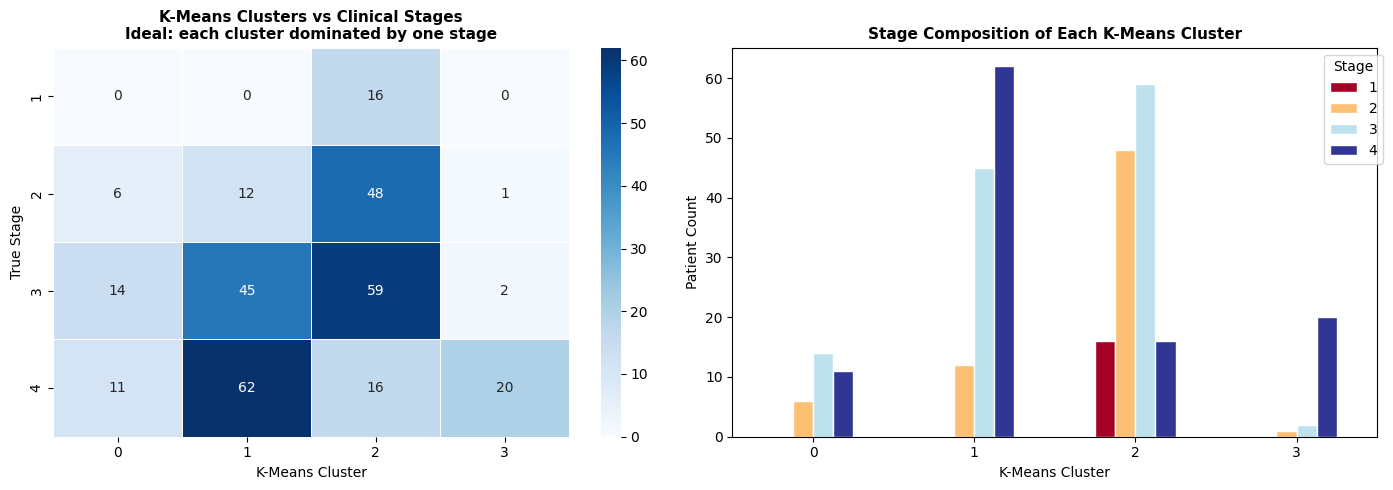

In [48]:
# Visualise cluster vs stage alignment
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap of crosstab
sns.heatmap(cross, annot=True, fmt='d', cmap='Blues',
            ax=axes[0], linewidths=0.5)
axes[0].set_title('K-Means Clusters vs Clinical Stages\n'
                  'Ideal: each cluster dominated by one stage',
                  fontsize=11, fontweight='bold')

# Cluster composition bar chart
cluster_stage = pd.DataFrame({
    'Cluster': cluster_labels,
    'Stage'  : le.inverse_transform(y)
})
cluster_stage.groupby(['Cluster','Stage']).size().unstack(fill_value=0).plot(
    kind='bar', ax=axes[1], colormap='RdYlBu', edgecolor='white', rot=0
)
axes[1].set_xlabel('K-Means Cluster')
axes[1].set_ylabel('Patient Count')
axes[1].set_title('Stage Composition of Each K-Means Cluster',
                  fontsize=11, fontweight='bold')
axes[1].legend(title='Stage', bbox_to_anchor=(1.02,1))

plt.tight_layout()
plt.show()


In [49]:
print("FEATURES:", FEATURES)
print("FINAL_FEATURES:", FINAL_FEATURES)
print("X_final shape:", X_final.shape)

FEATURES: ['Drug', 'Age', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin']
FINAL_FEATURES: ['Age', 'Albumin', 'Ascites', 'Bilirubin', 'Copper', 'Edema', 'Hepatomegaly', 'SGOT', 'Tryglicerides']
X_final shape: (312, 9)



---
## Section 8 — Limitations

While this project followed a rigorous and justified analytical pipeline, 
several dataset and methodological constraints limit the strength of conclusions 
that can be drawn.

### Dataset Constraints

| Limitation | Detail | Impact |
|---|---|---|
| **Small sample size** | 312 patients from a single Mayo Clinic trial (1974–1984) | Small cross-validation folds and limited generalisability |
| **Class imbalance** | Stage 1 severely underrepresented | Suppressed early-stage recall across models |

### Methodological Constraints

| Limitation | Detail | Impact |
|---|---|---|
| **Median imputation** | Applied to missing values | Introduces minor artificial homogeneity |
| **Beam Search (heuristic)** | Feature selection is path-dependent | Does not guarantee globally optimal subset |
| **GridSearchCV scope** | Limited to predefined parameter grid | Potentially better hyperparameters not explored |

### On the F1 Scores

The Macro F1 scores (0.32–0.46) reflect three compounding challenges operating 
simultaneously: severe Stage 1 imbalance, small overall sample size, and 
inherent clinical ambiguity between adjacent stages where biomarker profiles 
overlap. These are **dataset limitations beyond our control**, not 
modelling failures. The K-Means ARI of 0.083 independently confirms that 
biomarker data does not naturally separate into 4 clean clusters — validating 
why classification is genuinely difficult on this dataset.



## Section 9 — Conclusion

This study addressed the question: **can histologic cirrhosis stage be reliably predicted from routinely collected clinical and biochemical variables, and what is the minimal feature subset required to achieve this?**

Using the Mayo Clinic Primary Biliary Cirrhosis dataset (312 patients), an interpretable machine learning workflow was developed, incorporating preprocessing, exploratory data analysis, feature selection, classification and model interpretation.

---

### Summary of Results

| Component | Key Finding |
|---|---|
| **Preprocessing** | 106 non-trial patients removed; 312-patient cohort retained for reliable modelling |
| **EDA** | Key biomarkers (e.g. Albumin, Bilirubin) exhibit stage-related trends, indicating predictive signal |
| **Feature Selection** | Lasso and Beam Search identified a reduced subset of features with improved Macro F1 |
| **Best Model** | Tuned Random Forest achieved highest Macro F1 (0.4599) |
| **Model Comparison** | Logistic Regression showed more consistent performance across all stages, especially Stage 1 |
| **Interpretability (SHAP)** | Albumin, Bilirubin, Hepatomegaly and SGOT identified as most influential features |
| **Unsupervised Validation** | K-Means ARI = 0.083, indicating weak natural separation of stages |

---

### Key Insights

**1. Linear structure with non-linear gains.**  
While the tuned Random Forest achieved the highest Macro F1, Logistic Regression demonstrated more balanced performance across all stages, particularly for Stage 1 detection, suggesting that the dominant structure of the data is largely linear and can be captured with a simple model.

**2. Biomarker-only limitation.**  
The low K-Means ARI (0.083) confirms that blood biomarkers alone do not form clearly separable stage groups. This reflects both the continuous nature of cirrhosis progression and the absence of richer clinical inputs such as imaging, histology and underlying disease indicators.

**3. Robust and interpretable feature set.**  
Consistent findings across EDA, Lasso, Beam Search and SHAP identified Albumin, Bilirubin, Hepatomegaly and SGOT as key predictors, supporting their use as a minimal and clinically interpretable feature set for risk stratification.

---

### Recommendations for Future Work

| Recommendation | Tool | Justification |
|---|---|---|
| Address class imbalance | **SMOTE** | Improve recall for underrepresented Stage 1 cases |
| Incorporate survival information | **Survival Analysis (Kaplan-Meier, Cox Regression)** | Utilise N_Days appropriately without data leakage |
| Expand the dataset | Larger and more diverse cohort | Improve generalisability and increase Stage 1 representation |
| Include richer clinical data | Imaging, histology, underlying disease indicators | Overcome limitations of biomarker-only predictions |

---

### Final Remarks

This study demonstrates that an interpretable machine learning workflow can extract clinically meaningful insights from a small and imbalanced cirrhosis dataset, even when predictive performance is constrained by data and biological limitations. The convergence of EDA, feature selection and SHAP analysis identifies a consistent and minimal set of predictors Albumin, Bilirubin, Hepatomegaly and SGOT that can support practical risk stratification. Clinically, patients presenting with low Albumin, elevated Bilirubin and Hepatomegaly are more likely to be in advanced stages and should be prioritised for closer monitoring and intervention. 

While early-stage (Stage 1) prediction remains challenging due to severe class imbalance and overlapping biomarker profiles, the model is still able to provide indicative signals that can support early identification. This is particularly important, as intervention at Stage 1 offers the greatest opportunity to slow or halt disease progression, whereas later stages are largely irreversible. 

Future improvements will depend primarily on expanding the dataset, improving class balance, incorporating survival information and integrating richer clinical variables beyond blood biomarkers.